# Eye 엔드포인트 — 전체 실험 통합본 v2

**2026-11-08 갱신: 현재 성능 판단은 5부 production 검증과 6부 종합 결론을 기준으로 합니다.**

| 부 | 내용 | 해석 범위 |
|---|---|---|
| 1부 | EPA / EPA+GHS / GJC 통합 집계 | 기존 실행별 프로토콜 유지 |
| 2부 | Claude 00~06 | 과거 673행 평가·축소 격자 탐색 |
| 3부 | Claude 07~10 | 과거 탐색 결과 |
| 4부 | Claude 11 농도 복원 | 과거 5모델·2seed·축소 격자 결과 |
| **5부** | **농도 production 검증** | **606행 평가 + 67행 train-only, 6모델·3seed·20후보 전체 격자** |
| **6부** | **갱신된 종합 결론 및 학습·추론 상태** | **현재 판단과 한계** |

이번 갱신은 완료된 결과를 읽고 검증·집계한 작업입니다. 모델을 새로 학습하지 않았습니다.
**1~4부의 코드·저장 출력은 과거 기록으로 보존했습니다.** 이 출력들을 최신 production 결과로
해석하거나 서로 다른 모집단/격자의 최고점을 한 순위로 합치면 안 됩니다.
특히 4부의 '채택'과 최고 MCC 0.264는 당시 탐색 판단이며 현재 결론은 6부에서 갱신합니다.

5부는 앞부분을 실행하지 않아도, **5부 첫 코드 셀부터 순서대로 독립 실행**할 수 있습니다.
필요 자료는 이 노트북 옆 `claude/`에 둡니다. 신규 절에는 개인 절대경로가 없습니다.
1~4부의 기존 경로와 실행 환경까지 이 갱신에서 이식한 것은 아닙니다.


---
# 1부 — 통합 집계 (GJC)

# 모든 eye 모델 실험 통합 보고서

EPA, EPA+GHS, Claude 00~06, GJC MACCS 및 혼합물 화학 특징 실험을 하나로 수록합니다. **skin은 제외**합니다. 결과가 없는 실험은 완료로 취급하지 않습니다.

이 노트북의 전체 셀 실행은 저장된 결과를 다시 읽을 뿐이며 **모델을 학습하거나 원본 결과를 변경하지 않습니다.** 저장된 출력은 실행 당시 스냅샷입니다. 아래 모든 집계표는 생략 없이 수록하며, 개별 OOF/튜닝 체크포인트는 해당 실험 폴더에 보존되어 있습니다.

**과거 실행별 비교 규약입니다. 갱신된 production 규약은 5부를 따릅니다.**

## 비교 규약 및 주의점

- EPA와 EPA+GHS 기존 결과는 주로 673행 평가이며, 별도 GHS 학습 증강 여부를 구분해야 합니다.
- Claude 03은 기존/병합 그룹의 짝지은 비교이며 탐색 격자는 6개입니다. 발표 실행의 20개 격자 수치와 직접 비교하지 않습니다.
- GJC 실험은 606행, 추가 67행을 **학습과 평가 모두 제외**, 원본 전체에서 `merged_groups()` 계산 후 부분집합을 선택합니다. seed42, LR, 후보 6개, grouped nested 5×3 CV입니다.
- A는 EPA 1·2 vs 3·4, B는 EPA 1·2·3 vs 4입니다. EPA+GHS의 2A/2B는 별도 라벨 매핑 시나리오로 보존합니다.
- 서로 다른 프로토콜을 섞은 최고점 순위는 만들지 않습니다. 단일 seed의 작은 차이는 통계적으로 확정된 개선이 아닙니다.
- 01의 다수결 라벨 일치 결과는 **엄밀하게 증명된 최대 MCC 상한이 아닌 참고치**입니다.
- 02의 저장 OOF 기반 rank 앙상블은 **탐색적 결과**이며 엄격한 nested 앙상블 검증으로 인증하지 않습니다.
- 구조 기반 산·염기 특징은 실측 pH/pKa나 중화·계면활성 효과의 증거가 아닙니다.

### 반복 검증 프로토콜 추가

앞선 MACCS/화학 특징 탐색은 seed42·LR입니다. `gjc_mixture_repeat`은 기준 vs 화학 특징 추가를 LR/RF × seed42·202·777로 비교합니다. 전체 606행 외에 단일 성분 378행과 다성분 228행의 OOF를 나누어 평가하되 **같은 학습 모델과 임계값**을 사용합니다. 하위집단별 재학습·임계값 재선택은 하지 않습니다. 반복 실행에서는 분할과 모델 random_state를 함께 해당 seed로 설정합니다. 3개 seed의 평균/표준편차는 기술통계이며 독립 표본 기반 신뢰구간 또는 유의성 검정이 아닙니다. 세부 프로토콜은 실행별 metadata를 우선합니다.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, HTML
EYE_ROOT = Path('C:\\Users\\DS\\COS\\최종\\모델 실험\\eye')
LABEL_ROOT = Path('C:\\Users\\DS\\COS\\최종\\label 조합 변경')

def collect_sources(eye_root, label_root):
    import hashlib
    import io
    import json
    from datetime import datetime, timezone, timedelta

    import pandas as pd

    records, items = [], []

    def add(path, section, kind="json", required=False, eye_only=False):
        row = {
            "section": section,
            "path": str(path),
            "status": "missing",
            "sha256": None,
            "rows": None,
        }
        try:
            content = path.read_bytes()
            row["sha256"] = hashlib.sha256(content).hexdigest()
            row["bytes"] = len(content)
            if kind == "csv":
                obj = pd.read_csv(io.BytesIO(content))
                if eye_only:
                    if "endpoint" not in obj:
                        raise ValueError(
                            "EPA table missing endpoint; cannot safely exclude skin"
                        )
                    obj = obj.loc[obj.endpoint.astype(str).str.lower().eq("eye")].copy()
                row["rows"] = len(obj)
            elif kind == "text":
                obj = content.decode("utf-8-sig", errors="replace")
            else:
                obj = json.loads(content.decode("utf-8-sig"))
                if isinstance(obj, list) and all(isinstance(x, dict) for x in obj):
                    obj = pd.DataFrame(obj)
                    row["rows"] = len(obj)
            row["status"] = "available"
            items.append(
                {"section": section, "path": str(path), "kind": kind, "data": obj}
            )
        except FileNotFoundError:
            row["status"] = "not_yet_available" if required else "missing"
        except (OSError, ValueError, UnicodeError) as error:
            row["status"] = "unreadable_or_partial"
            row["error"] = str(error)
        records.append(row)
        return row

    for run in sorted((label_root / "EPA" / "runs").glob("*")):
        if not run.is_dir():
            continue
        section = "EPA | " + run.name
        table = run / "comparison_all_metrics.csv"
        if not table.exists():
            table = run / "comparison.csv"
        add(table, section, "csv", required=True, eye_only=True)
        for name in (
            "eye_completed.json",
            "scope_manifest.json",
            "comparison_manifest.json",
        ):
            if (run / name).exists():
                add(run / name, section)
        if not table.exists():
            records.append(
                {
                    "section": section,
                    "path": str(run),
                    "status": "historical_without_final_aggregate",
                    "note": "최종 집계 없음: 완료 모델로 취급하지 않음",
                }
            )

    for run in sorted((label_root / "EPA + GHS" / "runs").glob("*")):
        if not run.is_dir():
            continue
        section = "EPA+GHS | " + run.name
        for name in ("augmented_metrics.csv", "baseline_comparison.csv"):
            add(run / name, section, "csv", required=True)
        for name in ("completed.json", "final_audit.json"):
            if (run / name).exists():
                add(run / name, section)

    stage_names = [
        "00_diagnostics",
        "01_ceiling",
        "02_ensemble_saved_oof",
        "03_grouping_fix",
        "04_ordinal",
        "05_worst_actor",
        "06_representations",
    ]
    known = set()
    for name in stage_names:
        path = eye_root / "results" / (name + ".json")
        known.add(path)
        add(path, "Claude | " + name, required=True)
    for path in sorted((eye_root / "results").glob("*.json")):
        if path not in known:
            add(path, "Claude | " + path.stem)
    log = eye_root / "results" / "run.log"
    if log.exists():
        add(log, "Claude | execution_log", "text")
        text = items[-1]["data"] if items and items[-1]["path"] == str(log) else ""
        if isinstance(text, str) and "No usable candidate for xgb" in text:
            records.append(
                {
                    "section": "Claude | 04_ordinal",
                    "path": str(log),
                    "status": "failure_observed_in_log",
                    "note": "로그에 XGB 후보 실패 기록. 현재 프로세스 상태를 뜻하지 않음; 결과 파일 유무와 함께 해석.",
                }
            )

    for directory in sorted(eye_root.glob("gjc_mixture_*")):
        if not directory.is_dir():
            continue
        section = "GJC | " + directory.name
        runs = sorted({p.parent for p in directory.rglob("summary.csv")})
        if not runs:
            runs = [directory / "results"]
        for run in runs:
            subsection = section + " | " + str(run.relative_to(directory))
            add(run / "summary.csv", subsection, "csv", required=True)
            for name in (
                "paired_deltas.csv",
                "subgroup_metrics.csv",
                "seed_aggregate.csv",
            ):
                if (run / name).exists():
                    add(run / name, subsection, "csv")
            add(run / "metadata.json", subsection, required=True)
        for name in ("verification.json", "feature_support.json"):
            if (directory / name).exists():
                add(directory / name, section)

    timestamp = datetime.now(timezone(timedelta(hours=9))).isoformat()
    return {
        "snapshot_time": timestamp,
        "items": items,
        "inventory": pd.DataFrame(records),
    }


def display_section(snapshot, prefix):
    import json
    from html import escape

    import pandas as pd
    from IPython.display import HTML, Markdown, display

    for item in snapshot["items"]:
        if not item["section"].startswith(prefix):
            continue
        display(Markdown("### " + item["section"] + "\n\n`" + item["path"] + "`"))
        data = item["data"]
        if isinstance(data, pd.DataFrame):
            # All rows and columns are embedded, irrespective of pandas display limits.
            display(
                HTML(
                    data.to_html(index=False, max_rows=None, max_cols=None, escape=True)
                )
            )
        else:
            text = (
                data
                if isinstance(data, str)
                else json.dumps(data, ensure_ascii=False, indent=2)
            )
            display(
                HTML("<pre style='white-space:pre-wrap'>" + escape(text) + "</pre>")
            )
    status = snapshot["inventory"]
    status = status.loc[
        status.section.str.startswith(prefix) & status.status.ne("available")
    ]
    if not status.empty:
        display(Markdown("### 미완료·누락·실패 관측 기록"))
        display(HTML(status.to_html(index=False, escape=True)))

snapshot = collect_sources(EYE_ROOT, LABEL_ROOT)
print('결과 스냅샷:', snapshot['snapshot_time'])


결과 스냅샷: 2026-11-08T00:20:52.156741+09:00


## 1. EPA 단독 — eye 결과

완료 집계와 과거 미완료 실행을 구분합니다. 혼합 eye/skin 원본 표에서는 eye 행만 가져옵니다.

In [2]:
display_section(snapshot, 'EPA |')

### EPA | epa-production-20261106-no-catboost

`C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\comparison_all_metrics.csv`

endpoint,label,model,sensitivity,specificity,MCC,ROC-AUC,abs_gap,PR-AUC,precision,F1,balanced_accuracy,positive_count,negative_count,confusion_matrix,sensitivity_std,specificity_std,MCC_std,ROC-AUC_std
eye,A,lr,0.728000,0.737226,0.379523,0.738350,0.009226,0.389376,0.387234,0.505556,0.732613,125,548,"[[404, 144], [34, 91]]",0.110995,0.115325,0.114102,0.062593
eye,A,rf,0.672000,0.680657,0.281869,0.717956,0.008657,0.378600,0.324324,0.437500,0.676328,125,548,"[[373, 175], [41, 84]]",0.103537,0.122291,0.085631,0.070531
eye,A,et,0.648000,0.680657,0.263269,0.692161,0.032657,0.341175,0.316406,0.425197,0.664328,125,548,"[[373, 175], [44, 81]]",0.107331,0.068122,0.117560,0.095948
eye,A,svm,0.448000,0.828467,0.258340,0.669912,0.380467,0.331992,0.373333,0.407273,0.638234,125,548,"[[454, 94], [69, 56]]",0.414150,0.183952,0.245103,0.091091
eye,A,xgb,0.728000,0.614964,0.268165,0.677182,0.113036,0.375898,0.301325,0.426230,0.671482,125,548,"[[337, 211], [34, 91]]",0.130843,0.175693,0.141707,0.089151
eye,A,lgbm,0.728000,0.609489,0.263652,0.693672,0.118511,0.369978,0.298361,0.423256,0.668745,125,548,"[[334, 214], [34, 91]]",0.181989,0.099973,0.194589,0.112034
eye,B,lr,0.635294,0.576613,0.205798,0.611252,0.058681,0.682056,0.720000,0.675000,0.605954,425,248,"[[143, 105], [155, 270]]",0.022010,0.089612,0.104406,0.070929
eye,B,rf,0.654118,0.657258,0.301350,0.656044,0.003140,0.741707,0.765840,0.705584,0.655688,425,248,"[[163, 85], [147, 278]]",0.059175,0.097808,0.046140,0.040272
eye,B,et,0.656471,0.616935,0.265434,0.645332,0.039535,0.725971,0.745989,0.698373,0.636703,425,248,"[[153, 95], [146, 279]]",0.064115,0.066105,0.066656,0.037333
eye,B,svm,0.609412,0.556452,0.160776,0.596319,0.052960,0.685321,0.701897,0.652393,0.582932,425,248,"[[138, 110], [166, 259]]",0.216195,0.190723,0.059394,0.033553


### EPA | epa-production-20261106-no-catboost

`C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\eye_completed.json`

### EPA | epa-production-20261106-no-catboost

`C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\scope_manifest.json`

### EPA | epa-production-20261106-no-catboost

`C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\comparison_manifest.json`

### 미완료·누락·실패 관측 기록

section,path,status,sha256,rows,note,bytes
EPA | epa-production-20261106,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106\comparison.csv,not_yet_available,NaN,NaN,NaN,NaN
EPA | epa-production-20261106,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106,historical_without_final_aggregate,NaN,NaN,최종 집계 없음: 완료 모델로 취급하지 않음,NaN


## 2. EPA+GHS — 학습 증강 및 라벨 조합

증강 성능 전체표와 원래 EPA 기준 대비 비교표를 함께 보존합니다.

In [3]:
display_section(snapshot, 'EPA+GHS |')

### EPA+GHS | epa-ghs-eye-719c1efdda0b5a59

`C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\augmented_metrics.csv`

target,model,sensitivity,specificity,MCC,ROC-AUC,PR-AUC,precision,F1,balanced_accuracy,abs_gap,positive_count,negative_count,confusion_matrix,foldstd_sensitivity,foldstd_specificity,foldstd_MCC,foldstd_ROC-AUC
A_2B,lr,0.704000,0.728102,0.351815,0.726321,0.389996,0.371308,0.486188,0.716051,0.024102,125,548,"[[399, 149], [37, 88]]",0.128374,0.122497,0.141020,0.068514
A_2B,rf,0.656000,0.666058,0.256346,0.711927,0.382956,0.309434,0.420513,0.661029,0.010058,125,548,"[[365, 183], [43, 82]]",0.060663,0.120283,0.098354,0.074802
A_2B,et,0.648000,0.673358,0.256668,0.686818,0.348610,0.311538,0.420779,0.660679,0.025358,125,548,"[[369, 179], [44, 81]]",0.107331,0.108790,0.138566,0.090874
A_2B,svm,0.688000,0.543796,0.180288,0.633168,0.274442,0.255952,0.373102,0.615898,0.144204,125,548,"[[298, 250], [39, 86]]",0.259846,0.310468,0.224357,0.124031
A_2B,xgb,0.760000,0.583942,0.267729,0.678978,0.335308,0.294118,0.424107,0.671971,0.176058,125,548,"[[320, 228], [30, 95]]",0.084853,0.149823,0.117318,0.073129
A_2B,lgbm,0.640000,0.607664,0.194112,0.693496,0.357001,0.271186,0.380952,0.623832,0.032336,125,548,"[[333, 215], [45, 80]]",0.093808,0.136008,0.156766,0.107368
A_2A,lr,0.704000,0.729927,0.353643,0.726745,0.390737,0.372881,0.487535,0.716964,0.025927,125,548,"[[400, 148], [37, 88]]",0.128374,0.120424,0.140531,0.068105
A_2A,rf,0.616000,0.667883,0.226900,0.711036,0.388603,0.297297,0.401042,0.641942,0.051883,125,548,"[[366, 182], [48, 77]]",0.087636,0.109098,0.097010,0.074298
A_2A,et,0.640000,0.675182,0.252100,0.686102,0.351828,0.310078,0.417755,0.657591,0.035182,125,548,"[[370, 178], [45, 80]]",0.116619,0.111107,0.151197,0.093570
A_2A,svm,0.688000,0.547445,0.183131,0.633401,0.275247,0.257485,0.374728,0.617723,0.140555,125,548,"[[300, 248], [39, 86]]",0.259846,0.312664,0.228579,0.124283


### EPA+GHS | epa-ghs-eye-719c1efdda0b5a59

`C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\baseline_comparison.csv`

target,model,baseline_sensitivity,baseline_specificity,baseline_MCC,baseline_ROC-AUC,primary_sensitivity,primary_specificity,primary_MCC,primary_ROC-AUC,delta_sensitivity,delta_specificity,delta_MCC,delta_ROC-AUC,fold_delta_sensitivity,fold_delta_specificity,fold_delta_MCC,fold_delta_ROC-AUC
A_2B,lr,0.728000,0.737226,0.379523,0.738350,0.704000,0.728102,0.351815,0.726321,-0.024000,-0.009124,-0.027708,-0.012029,"[0.0, -0.040000000000000036, 0.0, -0.040000000000000036, -0.040000000000000036]","[-0.01834862385321101, 0.0, 0.02752293577981646, -0.00909090909090915, -0.045454545454545525]","[-0.015249054897677694, -0.03275370002476513, 0.03732582497008885, -0.038189877053310756, -0.08521357044016842]","[-0.016880733944954263, -0.0021818181818181737, -0.003302752293578126, -0.02509090909090894, 1.1102230246251565e-16]"
A_2B,rf,0.672000,0.680657,0.281869,0.717956,0.656000,0.666058,0.256346,0.711927,-0.016000,-0.014599,-0.025523,-0.006029,"[-0.039999999999999925, 0.0, -0.07999999999999996, -0.040000000000000036, 0.07999999999999996]","[0.02752293577981657, -0.0636363636363636, 0.01834862385321101, -0.018181818181818188, -0.036363636363636376]","[-0.007096707078219355, -0.058897221364207775, -0.04188221540929632, -0.04521425984725311, 0.02245298364059556]","[0.011743119266055202, 0.006545454545454521, -0.01174311926605498, -0.030909090909090886, -0.0036363636363636598]"
A_2B,et,0.648000,0.680657,0.263269,0.692161,0.648000,0.673358,0.256668,0.686818,0.000000,-0.007299,-0.006601,-0.005343,"[0.0, -0.039999999999999925, 0.0, 0.0, 0.039999999999999925]","[-0.00917431192660545, 0.018181818181818188, 0.00917431192660545, -0.09090909090909094, 0.036363636363636376]","[-0.007733159780885013, -0.011923416081380867, 0.00938518911559727, -0.07187507901875383, 0.06483010583046633]","[-0.007339449541284404, -0.016363636363636358, -0.013944954128440323, 0.0003636363636364548, 0.020727272727272594]"
A_2B,svm,0.448000,0.828467,0.258340,0.669912,0.688000,0.543796,0.180288,0.633168,0.240000,-0.284672,-0.078053,-0.036745,"[1.0, 0.52, 0.12, -0.4, -0.040000000000000036]","[-1.0, -0.3363636363636363, -0.0825688073394496, 0.08181818181818179, -0.09090909090909094]","[0.0, 0.1477170296736804, -0.01611837365264912, -0.24429803603586037, -0.10955727642010638]","[-0.003302752293577904, 0.013454545454545497, -0.0014678899082569696, -0.1843636363636364, -0.01200000000000001]"
A_2B,xgb,0.728000,0.614964,0.268165,0.677182,0.760000,0.583942,0.267729,0.678978,0.032000,-0.031022,-0.000437,0.001796,"[0.040000000000000036, 0.0, 0.0, 0.0, 0.12]","[0.01834862385321101, -0.027272727272727226, -0.04587155963302758, -0.009090909090909094, -0.09090909090909083]","[0.04543833023107752, -0.022777749354260135, -0.050106594120888914, -0.006593079436452848, 0.007977523250666085]","[0.019082568807339384, -0.021818181818181626, -0.014678899082568697, 0.01272727272727281, 0.034909090909091]"
A_2B,lgbm,0.728000,0.609489,0.263652,0.693672,0.640000,0.607664,0.194112,0.693496,-0.088000,-0.001825,-0.069540,-0.000175,"[-0.040000000000000036, -0.36, -0.20000000000000007, 0.0, 0.16000000000000003]","[-0.00917431192660545, 0.1454545454545455, 0.03669724770642202, -0.03636363636363632, -0.1454545454545455]","[-0.03838151347177296, -0.16219508016536613, -0.10888305150983318, -0.02824033591493417, 0.009527931672934267]","[0.031743119266055, -0.06872727272727275, -0.02091743119266065, -0.014909090909090983, 0.001636363636363658]"
A_2A,lr,0.728000,0.737226,0.379523,0.738350,0.704000,0.729927,0.353643,0.726745,-0.024000,-0.007299,-0.025880,-0.011606,"[0.0, -0.040000000000000036, 0.0, -0.040000000000000036, -0.040000000000000036]","[-0.00917431192660545, 0.0, 0.02752293577981646, -0.00909090909090915, -0.045454545454545525]","[-0.007672340247236897, -0.03275370002476513, 0.03732582497008885, -0.038189877053310756, -0.08521357044016842]","[-0.016146788990825778, 0.001454545454545375, -0.0029357798165139393, -0.02509090909090894, 0.0007272727272727986]"
A_2A,rf,0.672000,0.680657,0.281869,0.717956,0.61600

### EPA+GHS | epa-ghs-eye-719c1efdda0b5a59

`C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\completed.json`

### EPA+GHS | epa-ghs-eye-719c1efdda0b5a59

`C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\final_audit.json`

## 3. Claude eye 실험 00~06

진단, 다수결 일치 참고치, 탐색적 앙상블, 그룹 수정, 순서형, 최악 성분 및 특징 재조합을 구분합니다. 없는 결과는 대기/미완료이며 실행 로그의 실패 기록과 현재 실행 상태는 별개입니다.

In [4]:
display_section(snapshot, 'Claude |')

### 미완료·누락·실패 관측 기록

section,path,status,sha256,rows,note,bytes
Claude | 00_diagnostics,C:\Users\DS\COS\최종\모델 실험\eye\results\00_diagnostics.json,not_yet_available,NaN,NaN,NaN,NaN
Claude | 01_ceiling,C:\Users\DS\COS\최종\모델 실험\eye\results\01_ceiling.json,not_yet_available,NaN,NaN,NaN,NaN
Claude | 02_ensemble_saved_oof,C:\Users\DS\COS\최종\모델 실험\eye\results\02_ensemble_saved_oof.json,not_yet_available,NaN,NaN,NaN,NaN
Claude | 03_grouping_fix,C:\Users\DS\COS\최종\모델 실험\eye\results\03_grouping_fix.json,not_yet_available,NaN,NaN,NaN,NaN
Claude | 04_ordinal,C:\Users\DS\COS\최종\모델 실험\eye\results\04_ordinal.json,not_yet_available,NaN,NaN,NaN,NaN
Claude | 05_worst_actor,C:\Users\DS\COS\최종\모델 실험\eye\results\05_worst_actor.json,not_yet_available,NaN,NaN,NaN,NaN
Claude | 06_representations,C:\Users\DS\COS\최종\모델 실험\eye\results\06_representations.json,not_yet_available,NaN,NaN,NaN,NaN


## 4. GJC 독립 혼합물 실험

### MACCS
새 성분별 MACCS를 농도가중 평균으로 결합했습니다. 이진 비트 표준편차는 `sqrt(mean*(1-mean))`이므로 독립적인 상호작용 정보가 아닙니다.

### 화학 특징
카복실산/카복실레이트, 설폰산/설포네이트, 산성 P=O-OH/O− 구조(포스포네이트 포함), 중성 비아미드 아민, 방향족 질소, 4차 암모늄, 전하 원자 수와 성분 다양성을 사용했습니다. 아민은 니트릴·니트로·아미드·설폰아미드·포스포르아미드와 양전하 질소를 제외합니다. 4차 암모늄을 염기성 지표로 간주하지 않습니다. 서로 다른 성분의 공존 항은 같은 성분 내부의 산/염기 자기항을 제외합니다.

### 이번 실행 해석
화학 특징 추가는 A/B MCC와 AUC가 기준보다 소폭 상승했습니다. 공존 항 추가는 B를 악화시켰습니다. MACCS는 A MCC만 상승하고 AUC 및 B는 하락했습니다. 이는 seed42·LR의 관측이며 일반적인 우열/인과적 설명은 아닙니다. 표와 메타데이터가 원자료이며, 새 실행을 추가한 경우 이 설명도 재검토해야 합니다.

In [5]:
display_section(snapshot, 'GJC |')

## 5. 동일 GJC 실행 내부의 짝지은 차이

각 `summary.csv` 내부에서만 baseline 대비 차이를 계산합니다. 다른 프로토콜끼리 합산하지 않습니다.

In [6]:
for item in snapshot['items']:
    table = item['data']
    if item['section'].startswith('GJC |') and item['path'].endswith('summary.csv') and isinstance(table, pd.DataFrame) and 'variant' in table:
        keys = [k for k in ('label', 'model', 'seed', 'n') if k in table]
        metrics = [k for k in ('MCC', 'ROC-AUC', 'sensitivity', 'specificity') if k in table]
        base = table.loc[table.variant.eq('baseline'), keys + metrics]
        other = table.loc[~table.variant.eq('baseline'), ['variant'] + keys + metrics]
        paired = other.merge(base, on=keys, suffixes=('', '_baseline'), validate='many_to_one')
        for metric in metrics:
            paired['delta_' + metric] = paired[metric] - paired[metric + '_baseline']
        display(Markdown('### ' + item['section']))
        display(HTML(paired[['variant'] + keys + ['delta_' + k for k in metrics]].to_html(index=False, escape=True)))

## 6. 원자료 목록·읽기 상태·SHA-256

같은 바이트를 읽어 계산한 해시와 읽기 상태입니다. 파일 단위 스냅샷이며, 동시에 생성 중인 여러 파일에 대한 전역 원자적 스냅샷은 아닙니다. 누락/부분 파일은 명시합니다.

In [7]:
display(HTML(snapshot['inventory'].to_html(index=False, max_rows=None, max_cols=None, escape=True)))
print('집계 및 부속 자료 수:', len(snapshot['items']))
print('학습 실행 없음; 읽기 전용 보고서 완료')

section,path,status,sha256,rows,note,bytes
EPA | epa-production-20261106,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106\comparison.csv,not_yet_available,NaN,NaN,NaN,NaN
EPA | epa-production-20261106,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106,historical_without_final_aggregate,NaN,NaN,최종 집계 없음: 완료 모델로 취급하지 않음,NaN
EPA | epa-production-20261106-no-catboost,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\comparison_all_metrics.csv,available,ce102a9d1bfbd9ab84e95d0a3f2bd51bd40fa979339741dfda224f932bcfe1aa,12.0,NaN,7109.0
EPA | epa-production-20261106-no-catboost,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\eye_completed.json,available,8d28cb24bd75acdb7ea4131e569d7c3d0d95879c9a807f959e96d8a6a38028a3,NaN,NaN,211.0
EPA | epa-production-20261106-no-catboost,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\scope_manifest.json,available,7061f941318aa99e3321c29bf48c18a4a2fd73d7a4dcd24a95589d72bccecc15,NaN,NaN,1241.0
EPA | epa-production-20261106-no-catboost,C:\Users\DS\COS\최종\label 조합 변경\EPA\runs\epa-production-20261106-no-catboost\comparison_manifest.json,available,6e54b4faf0316dc1effe1a63c41c8d19103150d503278f2c9f2111d9b752ffef,NaN,NaN,333.0
EPA+GHS | epa-ghs-eye-719c1efdda0b5a59,C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\augmented_metrics.csv,available,4673710054f1d63ecec4be05e7685ed9a210ea9aba7b81ab02820aed1de09142,24.0,NaN,7114.0
EPA+GHS | epa-ghs-eye-719c1efdda0b5a59,C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\baseline_comparison.csv,available,5faac91c15ecc2b697e6be07af922a234b73c321736359185da28eeac1b4e278,24.0,NaN,15800.0
EPA+GHS | epa-ghs-eye-719c1efdda0b5a59,C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\completed.json,available,e7b5e9b7f30f9253ecec645aafb122b7e0dcf6e3ca36958e450bca04b4a54610,NaN,NaN,521.0
EPA+GHS | epa-ghs-eye-719c1efdda0b5a59,C:\Users\DS\COS\최종\label 조합 변경\EPA + GHS\runs\epa-ghs-eye-719c1efdda0b5a59\final_audit.json,available,902d608d5641c2a988bdc6f7ef42ac71c0b9a591be499d854a30918e636a7511,NaN,NaN,402.0


집계 및 부속 자료 수: 8
학습 실행 없음; 읽기 전용 보고서 완료


---
# 2부 — 모델 보강 실험 00~06 상세 (Claude)

여기서부터는 Claude가 수행한 여섯 개 실험의 상세 분석입니다.
1부가 '무슨 결과가 있는가'를 모았다면, 2부는 '그래서 무엇을 바꿔야 하는가'를 따집니다.

**과거 00~06 탐색 기록 — 아래 673행·6후보는 현재 production 프로토콜이 아닙니다.**

# Eye 모델 보강 실험

EPA eye 엔드포인트(673행 · 특성 2,265개)에서 모델을 보강할 방법을 찾기 위한 실험 묶음입니다.

**이 노트북이 하지 않는 것** — 기존 production 실행을 다시 돌리거나 덮어쓰지 않습니다.
무거운 계산은 전부 `run_experiments.py`가 수행해 `results/`에 캐시해 두었고,
여기서는 그 결과를 불러와 분석만 합니다.

## 프로토콜과 한계

| 항목 | 내용 |
|---|---|
| 교차검증 | 외부 5-fold × 내부 3-fold grouped nested CV (production과 동일 코드) |
| 임계값 | 내부 OOF에서 민감도–특이도 차 최소화 → MCC 최대화 → 작은 값 (외부 정답 미사용) |
| 표본 가중 | balanced sample weight |
| **후보 격자** | **20개 중 6개로 축소** — 계산량 때문. LR은 발표값과 정확히 일치하지만 SVM 등 일부는 다릅니다 |
| 유효한 비교 | **같은 프로토콜 안에서 짝지은 차이**만 의미가 있습니다. 발표된 절대 수치와 직접 비교하지 마십시오 |
| 반복 | seed 42 / 202 / 777 |

> 격자를 줄였기 때문에 이 노트북의 절대 수치는 `label 조합 변경/EPA` 의 발표 결과와 다를 수 있습니다.
> 모든 결론은 **같은 조건에서 A와 B를 나란히 돌린 차이**에 근거합니다.

In [8]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties, fontManager

ROOT = next(p for p in (Path.cwd(), Path.cwd() / "claude")
            if (p / "experiment_utils.py").exists())
sys.path.insert(0, str(ROOT))
import experiment_utils as X

FONT = Path("C:/Windows/Fonts/malgun.ttf")
fontManager.addfont(str(FONT))
plt.rcParams.update({
    "font.family": FontProperties(fname=FONT).get_name(),
    "axes.unicode_minus": False,
    "figure.dpi": 110,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

def load(name):
    return json.loads((X.RESULTS / f"{name}.json").read_text(encoding="utf-8"))

def frame(name):
    return pd.DataFrame(load(name))

df, M, cols = X.load_eye()
print("eye", M.shape, "| 등급 분포", df.final_label.value_counts().sort_index().to_dict())

eye (673, 2265) | 등급 분포 {1: 65, 2: 60, 3: 300, 4: 248}


---
## 00. 데이터 진단

실험을 설계하기 전에 데이터가 어떤 상태인지부터 확인합니다.
여기서 나오는 두 가지가 이후 모든 실험의 전제를 바꿉니다.

In [9]:
diag = load("00_diagnostics")
print(f"행 수                     {diag['n_rows']}")
print(f"고유 특징 벡터            {diag['n_unique_vectors']}")
print(f"중복 벡터 그룹            {diag['n_duplicate_groups']}개 / 포함 행 {diag['n_rows_in_duplicate_groups']}")
print(f"그룹 수 (기존 → 병합)     {diag['n_groups_original']} → {diag['n_groups_merged']}")
print()
print(f"★ 완전히 같은 특징 벡터인데 서로 다른 외부 fold에 흩어진 그룹: "
      f"{diag['n_straddling_groups']}개 / {diag['n_rows_straddling']}행 "
      f"({diag['n_rows_straddling']/diag['n_rows']*100:.1f}%)")
print()
print("evaluation_role :", diag["evaluation_role"])
print("weight_mode     :", diag["weight_mode"])
print("성분 수 분포     :", diag["n_components_used"])

행 수                     673
고유 특징 벡터            444
중복 벡터 그룹            102개 / 포함 행 331
그룹 수 (기존 → 병합)     425 → 415

★ 완전히 같은 특징 벡터인데 서로 다른 외부 fold에 흩어진 그룹: 8개 / 22행 (3.3%)

evaluation_role : {'existing_evaluation_pool': 606, 'augmentation_train_only': 67}
weight_mode     : {'pct_active_ingredient': 597, 'exact_disclosed_component_weighted': 67, 'equal_fallback_missing_pct': 9}
성분 수 분포     : {'1': 421, '2': 156, '3': 63, '4': 28, '5': 3, '6': 2}


In [10]:
pd.DataFrame(diag["straddling_detail"]).assign(
    n=lambda d: d["rows"].str.len()
)[["rows", "outer_folds", "epa_classes", "label_consistent", "n"]]

,rows,outer_folds,epa_classes,label_consistent,n
0,"[61, 224, 319, 321, 588, 591, 593]","[1, 1, 1, 1, 3, 3, 1]","[3, 1, 3, 3, 4, 4, 4]",False,7
1,"[125, 285]","[1, 2]","[1, 1]",True,2
2,"[232, 233]","[2, 1]","[3, 2]",False,2
3,"[254, 656]","[1, 0]","[3, 4]",False,2
4,"[606, 609]","[2, 0]","[3, 4]",False,2
5,"[617, 620]","[0, 2]","[4, 4]",True,2
6,"[623, 645]","[3, 4]","[4, 4]",True,2
7,"[629, 632, 633]","[3, 4, 4]","[3, 3, 3]",True,3


### 읽는 법

**1. 673행 중 331행이 중복입니다.** 고유한 특징 벡터는 444개뿐이라, 실효 표본 크기는 673보다 훨씬 작습니다.

**2. 그중 8개 그룹 22행이 외부 fold를 횡단합니다.** 완전히 같은 특징 벡터가 학습과 테스트에 동시에 존재한다는 뜻입니다.
`comp_group_id`도 `split_group_id`도 이들을 같은 그룹으로 묶지 못했습니다. 실험 03이 이걸 고칩니다.

**3. `evaluation_role`에 `augmentation_train_only`로 표시된 67행이 평가에 들어가 있습니다.**
이 노트북은 발표된 실행과 비교 가능하도록 673행을 그대로 쓰지만,
평가 분모를 606으로 할지 673으로 할지는 별도로 결정하셔야 합니다.

---
## 01. 성능 상한 — 무엇을 쫓을 가치가 있는가

같은 특징 벡터에 다른 등급이 붙어 있으면, 어떤 모델도 그 둘을 구분할 수 없습니다.
그 불일치만으로 결정되는 상한을 먼저 계산합니다.

이건 **필요조건 상한**입니다. 실제 성능은 중복 말고도 훨씬 많은 요인에 묶여 있으니,
"여기까지 갈 수 있다"가 아니라 "적어도 여기보다는 위로 못 간다"로 읽어야 합니다.

In [11]:
ceil = pd.DataFrame(load("01_ceiling"))
display(ceil.round(3))

published = {"A": 0.380, "B": 0.301}   # 발표된 eye 최고 MCC (LR / RF)
for row in ceil.to_dict("records"):
    lab = row["label"]
    print(f"라벨 {lab}: 현재 최고 MCC {published[lab]:.3f}  →  중복 노이즈 상한 {row['ceiling_MCC']:.3f}"
          f"   (여유 {row['ceiling_MCC']-published[lab]:+.3f}, 되돌릴 수 없는 오류 {row['irreducible_rate']*100:.1f}%)")

,label,irreducible_errors,irreducible_rate,rows_in_conflicted_vector_groups,ceiling_MCC,ceiling_sensitivity,ceiling_specificity,ceiling_balanced_accuracy
0,A,29,0.043,83,0.861,0.912,0.967,0.940
1,B,64,0.095,166,0.795,0.934,0.855,0.894


라벨 A: 현재 최고 MCC 0.380  →  중복 노이즈 상한 0.861   (여유 +0.481, 되돌릴 수 없는 오류 4.3%)
라벨 B: 현재 최고 MCC 0.301  →  중복 노이즈 상한 0.795   (여유 +0.494, 되돌릴 수 없는 오류 9.5%)


### 읽는 법

중복 라벨 불일치가 만드는 상한은 A가 MCC 0.86, B가 0.79입니다.
현재 최고가 0.38 / 0.30이므로 **중복과 라벨 노이즈는 지금의 병목이 아닙니다.**
여유가 크다는 건 표현(feature)과 모델 쪽에 아직 할 일이 남아 있다는 뜻입니다.

---
## 02. 앙상블 — 재학습 없이 얻는 이득

발표된 실행의 fold별 OOF 예측이 전부 저장돼 있습니다. 이걸 그대로 써서 모델을 섞어 봅니다.

**순위 평균(rank average)에는 적합되는 파라미터가 없으므로 pooled ROC-AUC는 편향되지 않습니다.**
임계값만 각 외부 fold마다 나머지 fold에서 고릅니다.

In [12]:
ens = frame("02_ensemble_saved_oof")
for lab in ("A", "B"):
    sub = ens[ens.label == lab].sort_values("ROC-AUC", ascending=False)
    print(f"\n── 라벨 {lab} ──")
    print(sub[["구성", "sensitivity", "specificity", "MCC", "ROC-AUC", "PR-AUC"]]
          .round(3).to_string(index=False))


── 라벨 A ──
                  구성  sensitivity  specificity   MCC  ROC-AUC  PR-AUC
               단일 lr        0.728        0.712 0.354    0.738   0.389
     앙상블 LR+LightGBM        0.680        0.668 0.277    0.736   0.411
  앙상블 LR+RF+LightGBM        0.696        0.682 0.302    0.734   0.395
        앙상블 6개 전체 평균        0.680        0.695 0.302    0.734   0.391
       앙상블 SVM 제외 5개        0.688        0.679 0.293    0.726   0.387
 앙상블 LR+XGB+LightGBM        0.672        0.650 0.254    0.720   0.390
               단일 rf        0.680        0.650 0.260    0.718   0.379
앙상블 트리 3개(RF/ET/XGB)        0.672        0.622 0.231    0.713   0.370
             단일 lgbm        0.648        0.608 0.200    0.694   0.370
               단일 et        0.648        0.637 0.225    0.692   0.341
              단일 xgb        0.656        0.562 0.170    0.677   0.376
              단일 svm        0.632        0.633 0.209    0.670   0.332

── 라벨 B ──
                  구성  sensitivity  specificity   MCC  ROC-AUC  PR-

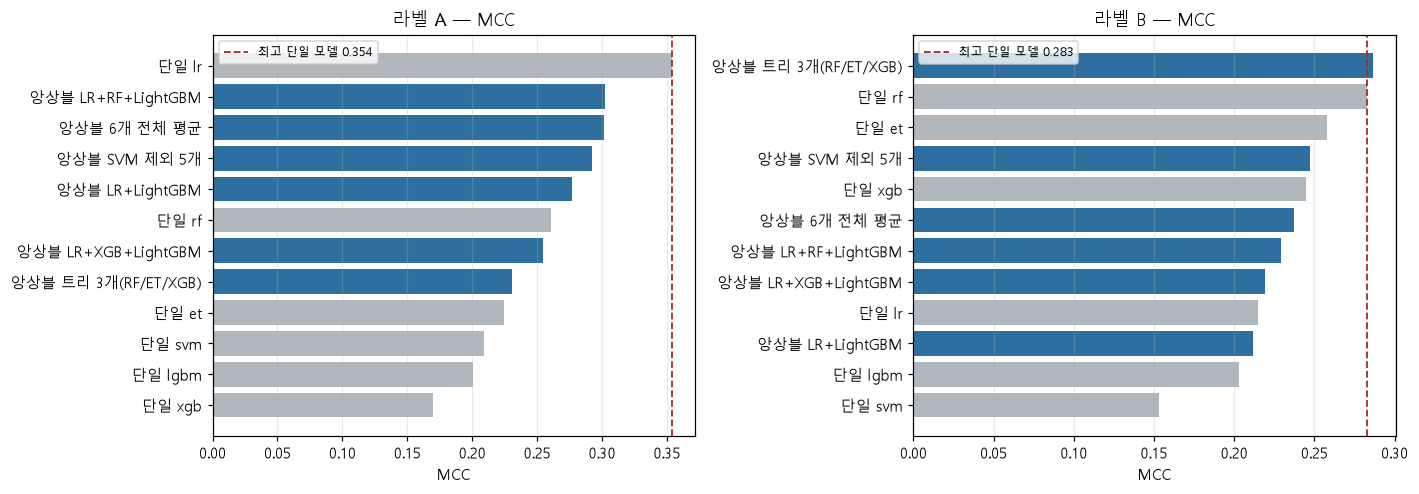

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, lab in zip(axes, ("A", "B")):
    sub = ens[ens.label == lab].sort_values("MCC")
    colors = ["#2f6f9f" if s.startswith("앙상블") else "#b0b7bd" for s in sub["구성"]]
    ax.barh(sub["구성"], sub["MCC"], color=colors)
    best_single = sub[sub["구성"].str.startswith("단일")]["MCC"].max()
    ax.axvline(best_single, color="#9c3030", ls="--", lw=1.2,
               label=f"최고 단일 모델 {best_single:.3f}")
    ax.set(title=f"라벨 {lab} — MCC", xlabel="MCC")
    ax.legend(fontsize=8)
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

**보존된 표·그래프 출력은 그룹화 1판입니다. 2판의 확인된 차이와 판정은 5부에 별도로 제시합니다.**

---
## 03. 분할 그룹화 수정 — 요청하신 실험

완전히 같은 특징 벡터를 같은 그룹으로 묶고 다시 돌렸을 때 수치가 얼마나 내려가는지 봅니다.

- **기존 그룹화**: `comp_group_id` 와 `split_group_id` 의 연결요소 (발표된 실행과 동일)
- **완전일치벡터 병합 (2판)**: 위에 더해 2,265차원 특징 벡터를 소수 6자리로 반올림한 값이 같은 행까지 연결

03의 2판과 04~11의 기존 캐시는 분할이 다릅니다. 기존 실험의 paired 비교에는
`03_grouping_fix_v1.json`을 사용합니다. 03은 증강 67행을 포함한 673행 CV이며,
606행 평가·증강 train-only production 검증과는 구별해야 합니다.
아래 저장 출력은 재실행 전까지 1판 수치입니다. 2판 판정은
`claude/results/03_grouping_fix_verdict.json`과 판별표를 기준으로 확인해야 합니다.

두 그룹화 모두 **같은 seed 3개**로 돌려서, 그룹화 때문에 생긴 차이와
분할 난수 때문에 생긴 차이를 분리합니다.

In [14]:
g = frame("03_grouping_fix")
summary = (g.groupby(["grouping", "label", "model"])[["MCC", "ROC-AUC", "sensitivity", "specificity"]]
             .mean().round(3).reset_index())
pivot = summary.pivot_table(index=["label", "model"], columns="grouping",
                            values=["MCC", "ROC-AUC"])
display(pivot.round(3))

MCC           ROC-AUC          
grouping    기존 그룹화 완전일치벡터 병합  기존 그룹화 완전일치벡터 병합
label model                                   
A     et     0.263     0.269   0.693     0.699
      lgbm   0.244     0.221   0.694     0.668
      lr     0.341     0.329   0.738     0.731
      rf     0.268     0.263   0.711     0.711
      svm    0.128     0.196   0.623     0.663
      xgb    0.253     0.225   0.694     0.675
B     et     0.232     0.250   0.627     0.638
      lgbm   0.187     0.151   0.629     0.619
      lr     0.169     0.146   0.586     0.578
      rf     0.243     0.242   0.644     0.644
      svm    0.106     0.044   0.558     0.529
      xgb    0.210     0.217   0.625     0.646

In [15]:
# seed 단위로 짝지은 차이 (병합 - 기존)
wide = g.pivot_table(index=["label", "model", "seed"], columns="grouping",
                     values=["MCC", "ROC-AUC", "sensitivity", "specificity"])
delta = pd.DataFrame({
    m: wide[(m, "완전일치벡터 병합")] - wide[(m, "기존 그룹화")]
    for m in ("MCC", "ROC-AUC", "sensitivity", "specificity")
}).reset_index()

per_model = (delta.groupby(["label", "model"])[["MCC", "ROC-AUC"]]
             .agg(["mean", "std"]).round(3))
display(per_model)

print("\n라벨별 요약 (seed 3개 × 모델 6개 = 18개 칸)")
for lab in ("A", "B"):
    sub = delta[delta.label == lab]
    print(f"  {lab}: ΔMCC 평균 {sub.MCC.mean():+.3f} (하락 {int((sub.MCC<0).sum())}/18) | "
          f"ΔAUC 평균 {sub['ROC-AUC'].mean():+.3f} (하락 {int((sub['ROC-AUC']<0).sum())}/18)")

MCC        ROC-AUC       
              mean    std    mean    std
label model                             
A     et     0.006  0.010   0.006  0.020
      lgbm  -0.023  0.045  -0.026  0.045
      lr    -0.013  0.016  -0.007  0.013
      rf    -0.005  0.029  -0.000  0.002
      svm    0.068  0.068   0.040  0.062
      xgb   -0.028  0.038  -0.019  0.030
B     et     0.019  0.042   0.011  0.046
      lgbm  -0.036  0.054  -0.010  0.046
      lr    -0.022  0.054  -0.008  0.053
      rf    -0.001  0.050   0.000  0.014
      svm   -0.062  0.037  -0.029  0.009
      xgb    0.007  0.006   0.021  0.034


라벨별 요약 (seed 3개 × 모델 6개 = 18개 칸)
  A: ΔMCC 평균 +0.001 (하락 10/18) | ΔAUC 평균 -0.001 (하락 10/18)
  B: ΔMCC 평균 -0.016 (하락 11/18) | ΔAUC 평균 -0.002 (하락 10/18)


C:\Users\DS\AppData\Local\Temp\ipykernel_15460\353865137.py:15: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()


C:\Users\DS\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


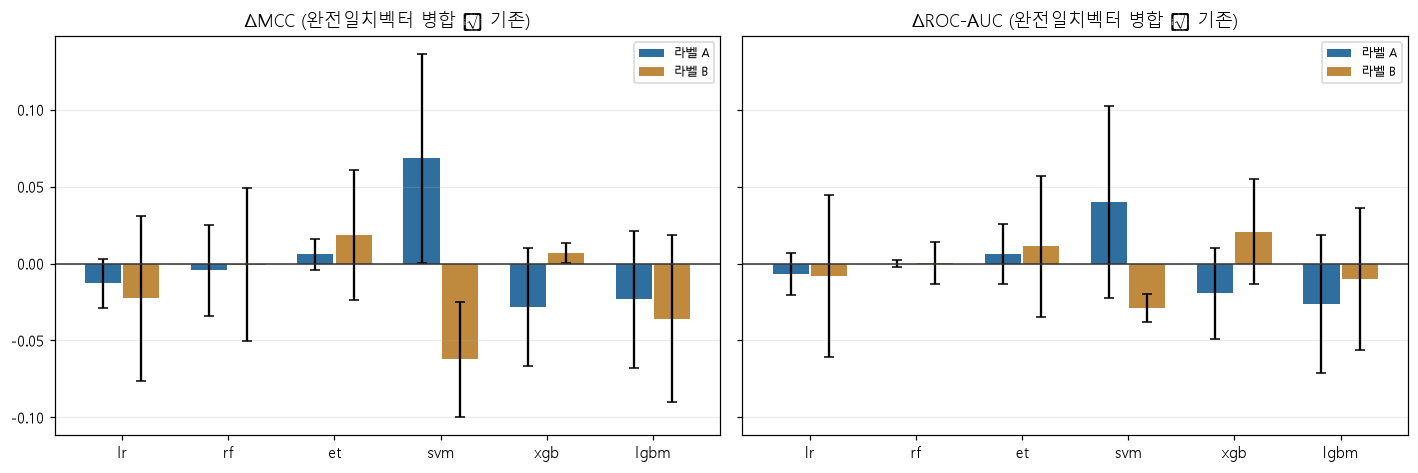

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, metric in zip(axes, ("MCC", "ROC-AUC")):
    for i, lab in enumerate(("A", "B")):
        sub = delta[delta.label == lab].groupby("model")[metric].agg(["mean", "std"])
        sub = sub.reindex(X.MODELS)
        pos = np.arange(len(sub)) + (i - 0.5) * 0.36
        ax.bar(pos, sub["mean"], 0.34, yerr=sub["std"], capsize=3,
               label=f"라벨 {lab}", color=["#2f6f9f", "#c08a3e"][i])
    ax.axhline(0, color="#333", lw=1)
    ax.set_xticks(np.arange(len(X.MODELS)))
    ax.set_xticklabels(X.MODELS)
    ax.set_title(f"Δ{metric} (완전일치벡터 병합 − 기존)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()

### 읽는 법

막대가 0보다 아래면 **그룹화를 고쳤을 때 성능이 내려갔다**는 뜻이고, 그 내려간 폭이
기존 분할이 과대평가하고 있던 양입니다. 오차 막대는 seed 3개의 표준편차이므로,
막대 길이가 오차 막대보다 짧으면 분할 난수와 구분되지 않는 수준입니다.

---
## 04. 4-class 순서형 라벨

EPA 등급은 1·2·3·4 순서형인데 지금은 A(≤2) 또는 B(≤3)로 이진화하면서 정보를 버립니다.
등급 4개를 그대로 다중분류로 학습한 뒤, 누적확률 P(≤2)와 P(≤3)로 A·B 점수를 유도합니다.
한 번의 적합으로 두 라벨을 모두 얻습니다.

비교 대상은 03의 **완전일치벡터 병합 그룹화 · 같은 seed**로 돌린 이진 모델입니다.

In [17]:
ordn = frame("04_ordinal")
g_v1 = frame("03_grouping_fix_v1")
binary = g_v1[g_v1.grouping == "완전일치벡터 병합"].copy()
binary["approach"] = "이진 (A 또는 B)"
both = pd.concat([
    binary[["approach", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
    ordn[["approach", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
], ignore_index=True)
both = both[both.model.isin(X.MULTICLASS_MODELS)]

display(both.groupby(["label", "model", "approach"])[["MCC", "ROC-AUC"]]
        .mean().round(3).unstack("approach"))

w = both.pivot_table(index=["label", "model", "seed"], columns="approach",
                     values=["MCC", "ROC-AUC"])
d4 = pd.DataFrame({
    m: w[(m, "4-class 순서형")] - w[(m, "이진 (A 또는 B)")] for m in ("MCC", "ROC-AUC")
}).reset_index()
print("\n순서형 − 이진, 짝지은 차이")
for lab in ("A", "B"):
    s = d4[d4.label == lab]
    print(f"  {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)}) | "
          f"ΔAUC {s['ROC-AUC'].mean():+.3f} (개선 {int((s['ROC-AUC']>0).sum())}/{len(s)})")

MCC                 ROC-AUC            
approach    4-class 순서형 이진 (A 또는 B) 4-class 순서형 이진 (A 또는 B)
label model                                                
A     et          0.280       0.269       0.705       0.699
      lgbm        0.229       0.221       0.693       0.668
      lr          0.328       0.329       0.728       0.731
      rf          0.275       0.263       0.720       0.711
      xgb         0.251       0.225       0.669       0.675
B     et          0.218       0.250       0.632       0.638
      lgbm        0.189       0.151       0.633       0.619
      lr          0.234       0.146       0.627       0.578
      rf          0.194       0.242       0.631       0.644
      xgb         0.197       0.217       0.627       0.646


순서형 − 이진, 짝지은 차이
  A: ΔMCC +0.011 (개선 14/15) | ΔAUC +0.006 (개선 8/15)
  B: ΔMCC +0.005 (개선 7/15) | ΔAUC +0.005 (개선 6/15)


---
## 05. 최악 성분(worst-actor) 표현

production 특징은 성분 fingerprint를 **농도로 가중 평균**합니다.
그런데 자극성은 보통 **가장 공격적인 성분 하나**가 좌우하므로, 평균은 그 신호를 희석시킵니다.

- fingerprint: 성분별 max pooling (어느 성분에든 있으면 1)
- descriptor: 가중치가 가장 큰 성분의 값

성분 출처가 있는 행만 바뀌고 나머지는 그대로 둡니다.
두 표현의 분할은 **동일하게 고정**해서 표현 효과만 분리합니다.

In [18]:
cov = json.loads((X.RESULTS / "05_worst_actor_coverage.json").read_text(encoding="utf-8"))
print("성분 출처가 있어 재인코딩된 행 :", cov["rows_with_component_provenance"])
print("그중 실제 다성분 행           :", cov["multi_component_rows_changed"])
print("그대로 둔 행                  :", cov["rows_unchanged"])

# 기존 05와 같은 분할인 03 1판을 사용한다.
wa = frame("05_worst_actor")
g_v1 = frame("03_grouping_fix_v1")
base_arm = g_v1[(g_v1.grouping == "완전일치벡터 병합") & (g_v1.seed.isin(sorted(wa.seed.unique())))].copy()
base_arm["표현"] = "기준 농도가중"
wa = pd.concat([
    wa[["표현", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
    base_arm[["표현", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
], ignore_index=True)
display(wa.groupby(["label", "model", "표현"])[["MCC", "ROC-AUC"]].mean().round(3).unstack("표현"))

w5 = wa.pivot_table(index=["label", "model", "seed"], columns="표현",
                    values=["MCC", "ROC-AUC"])
d5 = pd.DataFrame({
    m: w5[(m, "최악 성분 pooling")] - w5[(m, "기준 농도가중")] for m in ("MCC", "ROC-AUC")
}).reset_index()
print("\n최악 성분 − 기준, 짝지은 차이")
for lab in ("A", "B"):
    s = d5[d5.label == lab]
    print(f"  {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)}) | "
          f"ΔAUC {s['ROC-AUC'].mean():+.3f} (개선 {int((s['ROC-AUC']>0).sum())}/{len(s)})")

성분 출처가 있어 재인코딩된 행 : 606
그중 실제 다성분 행           : 228
그대로 둔 행                  : 67


MCC               ROC-AUC              
표현          기준 농도가중 최악 성분 pooling 기준 농도가중 최악 성분 pooling
label model                                            
A     et      0.260         0.272   0.691         0.703
      lgbm    0.227         0.189   0.673         0.645
      lr      0.329         0.309   0.730         0.730
      rf      0.267         0.240   0.713         0.686
      svm     0.196         0.183   0.673         0.614
      xgb     0.226         0.226   0.676         0.683
B     et      0.252         0.228   0.643         0.628
      lgbm    0.141         0.209   0.619         0.643
      lr      0.140         0.148   0.568         0.602
      rf      0.237         0.212   0.648         0.637
      svm     0.060         0.128   0.535         0.570
      xgb     0.225         0.204   0.647         0.642


최악 성분 − 기준, 짝지은 차이
  A: ΔMCC -0.014 (개선 4/12) | ΔAUC -0.016 (개선 5/12)
  B: ΔMCC +0.012 (개선 6/12) | ΔAUC +0.010 (개선 8/12)


---
## 06. 특징 집합 재조합

특성이 2,265개인데 표본이 673개입니다(p ≫ n). 발표된 결과에서 **LR이 트리 계열을 전부 이긴 것**은
정규화가 핵심이고 트리가 희소 이진 특징에서 과적합한다는 신호입니다. 특징을 줄이면 어떻게 되는지 봅니다.

새 descriptor를 계산하지는 않고, **기존 2,265개를 재조합**만 합니다.

In [19]:
rep = frame("06_representations")
tab = (rep.groupby(["label", "특징집합", "n_features", "model"])[["MCC", "ROC-AUC"]]
       .mean().round(3).reset_index())
for lab in ("A", "B"):
    print(f"\n── 라벨 {lab} ──")
    print(tab[tab.label == lab].pivot_table(
        index=["특징집합", "n_features"], columns="model", values="MCC"
    ).round(3).to_string())


── 라벨 A ──
model                          lgbm     lr    xgb
특징집합              n_features                     
descriptor만 217   217         0.205  0.255  0.240
fingerprint만 2048 2048        0.263  0.321  0.256
fp1024 접기+desc    1241        0.233  0.328  0.231
기준 fp2048+desc217 2265        0.227  0.329  0.226
물성 22+fp1024      1046        0.290  0.335  0.270
물성 소수집합 22        22          0.205  0.204  0.210

── 라벨 B ──
model                          lgbm     lr    xgb
특징집합              n_features                     
descriptor만 217   217         0.199  0.170  0.232
fingerprint만 2048 2048        0.198  0.148  0.149
fp1024 접기+desc    1241        0.192  0.167  0.209
기준 fp2048+desc217 2265        0.141  0.140  0.225
물성 22+fp1024      1046        0.149  0.153  0.156
물성 소수집합 22        22          0.138  0.172  0.094


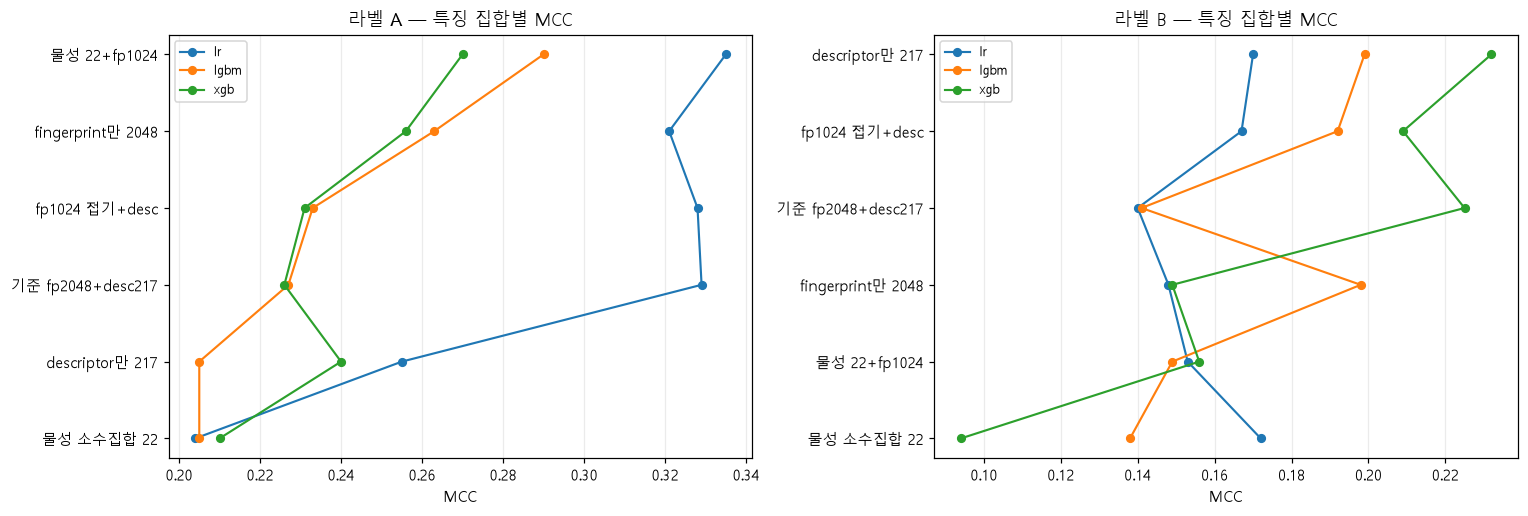

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False)
for ax, lab in zip(axes, ("A", "B")):
    sub = tab[tab.label == lab]
    order = (sub.groupby("특징집합")["MCC"].mean().sort_values().index)
    for model in ["lr", "lgbm", "xgb"]:
        s = sub[sub.model == model].set_index("특징집합").reindex(order)
        ax.plot(s["MCC"], s.index, "o-", label=model, lw=1.4, ms=5)
    ax.set(title=f"라벨 {lab} — 특징 집합별 MCC", xlabel="MCC")
    ax.grid(axis="x", alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()

**과거 2부 종합입니다. 전체 최신 종합 결론은 6부에 있습니다.**

---
## 종합

In [21]:
lines = []

d = delta.groupby("label")[["MCC", "ROC-AUC"]].mean()
lines.append("【03 분할 그룹화 수정】")
for lab in ("A", "B"):
    n_down = int((delta[delta.label == lab].MCC < 0).sum())
    lines.append(f"  라벨 {lab}: ΔMCC {d.loc[lab,'MCC']:+.3f}, ΔAUC {d.loc[lab,'ROC-AUC']:+.3f} "
                 f"(18칸 중 {n_down}칸 하락)")

lines.append("\n【01 상한】")
for row in ceil.to_dict("records"):
    lines.append(f"  라벨 {row['label']}: 중복 노이즈 상한 MCC {row['ceiling_MCC']:.3f} "
                 f"— 현재 최고와의 여유가 큼")

lines.append("\n【02 앙상블】")
for lab in ("A", "B"):
    sub = ens[ens.label == lab]
    best_e = sub[sub["구성"].str.startswith("앙상블")].sort_values("MCC").iloc[-1]
    best_s = sub[sub["구성"].str.startswith("단일")].sort_values("MCC").iloc[-1]
    lines.append(f"  라벨 {lab}: 최고 앙상블 {best_e['구성']} MCC {best_e.MCC:.3f} "
                 f"vs 최고 단일 {best_s['구성']} MCC {best_s.MCC:.3f} "
                 f"({best_e.MCC - best_s.MCC:+.3f})")

lines.append("\n【04 순서형】")
for lab in ("A", "B"):
    s = d4[d4.label == lab]
    lines.append(f"  라벨 {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)})")

lines.append("\n【05 최악 성분 표현】")
for lab in ("A", "B"):
    s = d5[d5.label == lab]
    lines.append(f"  라벨 {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)})")

lines.append("\n【06 특징 집합】 라벨별 최고 조합")
for lab in ("A", "B"):
    s = tab[tab.label == lab].sort_values("MCC").iloc[-1]
    base = tab[(tab.label == lab) & (tab["특징집합"] == "기준 fp2048+desc217")
               & (tab.model == s.model)]["MCC"].iloc[0]
    lines.append(f"  라벨 {lab}: {s['특징집합']} ({s.n_features}개) + {s.model} "
                 f"MCC {s.MCC:.3f} (같은 모델 기준 대비 {s.MCC - base:+.3f})")

print("\n".join(lines))

【03 분할 그룹화 수정】
  라벨 A: ΔMCC +0.001, ΔAUC -0.001 (18칸 중 10칸 하락)
  라벨 B: ΔMCC -0.016, ΔAUC -0.002 (18칸 중 11칸 하락)

【01 상한】
  라벨 A: 중복 노이즈 상한 MCC 0.861 — 현재 최고와의 여유가 큼
  라벨 B: 중복 노이즈 상한 MCC 0.795 — 현재 최고와의 여유가 큼

【02 앙상블】
  라벨 A: 최고 앙상블 앙상블 LR+RF+LightGBM MCC 0.302 vs 최고 단일 단일 lr MCC 0.354 (-0.052)
  라벨 B: 최고 앙상블 앙상블 트리 3개(RF/ET/XGB) MCC 0.287 vs 최고 단일 단일 rf MCC 0.283 (+0.004)

【04 순서형】
  라벨 A: ΔMCC +0.011 (개선 14/15)
  라벨 B: ΔMCC +0.005 (개선 7/15)

【05 최악 성분 표현】
  라벨 A: ΔMCC -0.014 (개선 4/12)
  라벨 B: ΔMCC +0.012 (개선 6/12)

【06 특징 집합】 라벨별 최고 조합
  라벨 A: 물성 22+fp1024 (1046개) + lr MCC 0.335 (같은 모델 기준 대비 +0.006)
  라벨 B: descriptor만 217 (217개) + xgb MCC 0.232 (같은 모델 기준 대비 +0.007)


### 해석의 한계

- 후보 격자를 20개 중 6개로 줄였습니다. **절대 수치는 발표된 production 결과와 다를 수 있고**,
  여기서 유효한 것은 같은 조건에서 짝지어 비교한 차이뿐입니다.
- seed 2~3개의 표준편차는 신뢰구간이 아닙니다. 통계적 유의성을 선언하지 않습니다.
- 05는 성분 출처가 있는 606행에만 영향을 주며, 실제 다성분 행은 그보다 적습니다.
- 모두 내부 교차검증 결과입니다. 외부 독립 데이터 검증이나 배포 성능 보장이 아닙니다.
- 중복 673→444행 문제는 03이 분할만 고쳤을 뿐, 행을 합치거나 가중치를 낮추지는 않았습니다.

---
# 3부 — 2차 실험 07~10 (Claude)

1부가 결과를 모으고 2부가 여섯 실험을 분석했다면, 3부는 2부에서 "다음에 해볼 것"으로
남겨 둔 항목을 실제로 돌린 결과입니다.

| # | 실험 | 2부에서 남긴 숙제 |
|---|---|---|
| **07** | 표현 결합 | 05에서 A는 농도가중, B는 최악성분이 좋았다. 둘 다 주면 모델이 고를까 |
| **08** | 확률 보정 | SVM이 raw margin이라 쓸 수 없었다. Platt/Isotonic으로 살릴 수 있나 |
| **09** | 다른 분자 표현 | 2부는 기존 특징 재조합만 했다. 새 지문 계열은 어떤가 |
| **10** | 접근법 교차 앙상블 | 순서형 LR과 이진 트리는 틀리는 패턴이 다를까 |

코드와 원시 결과는 `claude/` 아래에 있습니다
(`advanced_utils.py`, `run_advanced.py`, `results/07~10.json`).

> 2부와 같은 프로토콜입니다: 완전일치벡터 병합 그룹화, 축소 격자(20개 중 6개),
> 외부 5-fold × 내부 3-fold. 판단 기준도 같습니다 - **seed 변동(MCC ±0.024)보다
> 작은 차이는 효과로 보지 않습니다.**

In [22]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd

# 파일이 claude/ 아래로 옮겨졌을 수도, 노트북과 같은 칸에 있을 수도 있습니다.
CLAUDE = next(p for p in (Path.cwd() / "claude", Path.cwd())
              if (p / "advanced_utils.py").exists())
sys.path.insert(0, str(CLAUDE))
import advanced_utils as A

RESULTS = CLAUDE / "results"

def adv(name):
    return pd.DataFrame(json.loads((RESULTS / f"{name}.json").read_text(encoding="utf-8")))

def advmeta(name):
    return json.loads((RESULTS / f"{name}.json").read_text(encoding="utf-8"))

if "frame" not in dir():          # 2부 설정 셀을 건너뛰고 3부만 실행한 경우
    def frame(name):
        return adv(name)

SEED_SD = 0.024   # 2부 실험 03에서 측정한 seed 변동 표준편차 (MCC)
print("3부 결과 로드 준비 완료")

3부 결과 로드 준비 완료


## 07. 표현 결합 — 농도가중과 최악성분을 둘 다 주면

2부 실험 05는 라벨에 따라 정반대 결과를 냈습니다. A는 농도 가중 평균이, B는 최악 성분
pooling이 좋았습니다. 그렇다면 **둘 중 하나를 고르는 대신 둘 다 특징으로 주고 모델이
쓸 것을 고르게** 하면 어떨까요.

각 지문 블록을 1024비트로 접어 붙였기 때문에 전체 폭이 1024+1024+217 = 2,265개로
**기준 특징과 정확히 같습니다.** 특징 개수가 아니라 표현 방식만 달라진 비교입니다.

In [23]:
cov7 = advmeta("07_coverage")
print(f"결합 행렬 {cov7['n_features']}개 특징 | 성분 출처 보유 {cov7['rows_with_component_provenance']}행 "
      f"| 실제 다성분 {cov7['multi_component_rows']}행")

c7 = adv("07_combined_representation")
base = frame("03_grouping_fix_v1")  # 07 remains a first-edition experiment.
base = base[(base.grouping == "완전일치벡터 병합") & (base.seed.isin(sorted(c7.seed.unique())))].copy()
base["표현"] = "기준 농도가중"
cols = ["표현", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]
both7 = pd.concat([base[cols], c7[cols]], ignore_index=True)

display(both7.groupby(["label", "model", "표현"])[["MCC", "ROC-AUC"]].mean().round(3).unstack("표현"))

w7 = both7.pivot_table(index=["label", "model", "seed"], columns="표현", values=["MCC", "ROC-AUC"])
d7 = pd.DataFrame({m: w7[(m, "결합(농도가중+최악성분)")] - w7[(m, "기준 농도가중")]
                   for m in ("MCC", "ROC-AUC")}).reset_index()
print("\n결합 - 기준, 짝지은 차이")
for lab in ("A", "B"):
    s = d7[d7.label == lab]
    print(f"  {lab}: dMCC {s.MCC.mean():+.4f} (개선 {int((s.MCC>0).sum())}/{len(s)}) | "
          f"dAUC {s['ROC-AUC'].mean():+.4f} | seed 변동 기준 {SEED_SD}")

결합 행렬 2265개 특징 | 성분 출처 보유 606행 | 실제 다성분 228행


MCC               ROC-AUC        
표현          결합(농도가중+최악성분) 기준 농도가중 결합(농도가중+최악성분) 기준 농도가중
label model                                            
A     et            0.293   0.260         0.707   0.691
      lgbm          0.223   0.227         0.683   0.673
      lr            0.331   0.329         0.742   0.730
      rf            0.246   0.267         0.720   0.713
      svm           0.238   0.196         0.671   0.673
      xgb           0.256   0.226         0.688   0.676
B     et            0.236   0.252         0.647   0.643
      lgbm          0.180   0.141         0.644   0.619
      lr            0.157   0.140         0.589   0.568
      rf            0.260   0.237         0.658   0.648
      svm           0.131   0.060         0.574   0.535
      xgb           0.237   0.225         0.637   0.647


결합 - 기준, 짝지은 차이
  A: dMCC +0.0140 (개선 9/12) | dAUC +0.0092 | seed 변동 기준 0.024
  B: dMCC +0.0244 (개선 8/12) | dAUC +0.0150 | seed 변동 기준 0.024


In [24]:
# 05의 '최악 성분만' 결과와도 나란히 비교한다
wa = frame("05_worst_actor")
cols5 = ["label", "seed", "model", "MCC", "ROC-AUC"]
three = pd.concat([
    base[cols5].assign(표현="① 농도가중(기준)"),
    wa[wa.seed.isin(sorted(c7.seed.unique()))][cols5].assign(표현="② 최악성분만"),
    c7[cols5].assign(표현="③ 결합"),
], ignore_index=True)
piv = three.groupby(["label", "표현"])[["MCC", "ROC-AUC"]].mean().round(3)
display(piv)
print("\n라벨별 최고 표현:")
for lab in ("A", "B"):
    s = piv.loc[lab].sort_values("MCC", ascending=False)
    print(f"  {lab}: {s.index[0]} (MCC {s.iloc[0]['MCC']:.3f})")

MCC  ROC-AUC
label 표현                        
A     ① 농도가중(기준)  0.251    0.693
      ② 최악성분만     0.237    0.677
      ③ 결합        0.265    0.702
B     ① 농도가중(기준)  0.176    0.610
      ② 최악성분만     0.188    0.620
      ③ 결합        0.200    0.625


라벨별 최고 표현:
  A: ③ 결합 (MCC 0.265)
  B: ③ 결합 (MCC 0.200)


## 08. 확률 보정 — SVM을 쓸 수 있게 만들기

SVM은 확률이 아니라 decision margin을 내놓습니다. 그 값은 fold마다 척도가 달라서
합쳐 놓은 ROC/PR을 그대로 믿을 수 없고(기존 보고서도 "기술적 순위 요약"이라고만 했습니다),
임계값을 고르기도 불안정했습니다.

**내부 OOF 점수만으로** 보정 함수를 적합한 뒤 외부 점수에 적용합니다. 외부 정답을
쓰지 않으므로 누수가 없습니다. 임계값도 보정된 점수에서 다시 고릅니다.

In [25]:
c8 = adv("08_calibration")
c8["abs_gap"] = (c8.sensitivity - c8.specificity).abs()   # 민감도-특이도 균형
display(c8.groupby(["label", "model", "보정"])[["MCC", "ROC-AUC", "abs_gap"]]
        .mean().round(3).unstack("보정"))

w8 = c8.pivot_table(index=["label", "model", "seed"], columns="보정",
                    values=["MCC", "ROC-AUC", "abs_gap", "foldstd_MCC"])
print("보정 없음 대비 짝지은 차이")
for kind in ("Platt", "Isotonic"):
    for lab in ("A", "B"):
        for model in ("svm", "lr", "lgbm"):
            try:
                sub = w8.loc[lab].loc[model]
            except KeyError:
                continue
            dm = (sub[("MCC", kind)] - sub[("MCC", "보정 없음")]).mean()
            da = (sub[("ROC-AUC", kind)] - sub[("ROC-AUC", "보정 없음")]).mean()
            dsd = (sub[("foldstd_MCC", kind)] - sub[("foldstd_MCC", "보정 없음")]).mean()
            print(f"  {kind:9} {lab} {model:5} dMCC {dm:+.3f}  dAUC {da:+.3f}  "
                  f"fold변동 {dsd:+.3f}")

MCC                ROC-AUC                abs_gap              
보정          Isotonic  Platt  보정 없음 Isotonic  Platt  보정 없음 Isotonic  Platt  보정 없음
label model                                                                     
A     lgbm     0.222  0.221  0.221    0.682  0.682  0.668    0.120  0.047  0.047
      lr       0.327  0.329  0.329    0.720  0.730  0.731    0.021  0.026  0.026
      svm      0.191  0.188  0.196    0.667  0.652  0.663    0.242  0.318  0.228
B     lgbm     0.160  0.151  0.151    0.606  0.609  0.619    0.141  0.072  0.072
      lr       0.150  0.146  0.146    0.576  0.574  0.578    0.067  0.062  0.062
      svm      0.031  0.044  0.044    0.535  0.538  0.529    0.136  0.126  0.126

보정 없음 대비 짝지은 차이
  Platt     A svm   dMCC -0.009  dAUC -0.011  fold변동 +0.000
  Platt     A lr    dMCC +0.000  dAUC -0.002  fold변동 +0.000
  Platt     A lgbm  dMCC +0.000  dAUC +0.014  fold변동 +0.000
  Platt     B svm   dMCC +0.000  dAUC +0.009  fold변동 +0.000
  Platt     B lr    dMCC +0.000  dAUC -0.004  fold변동 +0.000
  Platt     B lgbm  dMCC +0.000  dAUC -0.010  fold변동 +0.000
  Isotonic  A svm   dMCC -0.005  dAUC +0.004  fold변동 -0.007
  Isotonic  A lr    dMCC -0.002  dAUC -0.011  fold변동 -0.005
  Isotonic  A lgbm  dMCC +0.002  dAUC +0.014  fold변동 -0.023
  Isotonic  B svm   dMCC -0.013  dAUC +0.006  fold변동 +0.010
  Isotonic  B lr    dMCC +0.004  dAUC -0.002  fold변동 +0.011
  Isotonic  B lgbm  dMCC +0.008  dAUC -0.013  fold변동 +0.008


**보정이 가장 중요한 지점은 MCC가 아니라 fold 변동입니다.** 점수가 공통 척도로 올라오면
임계값이 fold마다 덜 흔들립니다. 위 표의 `fold변동` 열이 음수이면 그만큼 안정해졌다는 뜻입니다.

## 09. 다른 분자 표현 계열 - 중단

Morgan 외에 MACCS/Avalon/AtomPair/Torsion/RDKitFP 다섯 계열을 비교하려 했으나
**실행 도중 중단했습니다.** 360개 작업 중 60개만 끝난 시점에서 남은 시간이 약 2시간으로
추정됐고, 이 실험만 **606행**(성분 출처가 있는 행)에서 평가하도록 설계되어 다른 단계의
673행 결과와 절대 수치를 비교할 수 없었습니다. 비교 가능한 범위가 좁은 데 비해
비용이 커서 제외했습니다.

다시 돌리려면 `run_advanced.py`의 `SKIP` 집합에서 `"09_fingerprint_families"`를 빼면 됩니다.
코드(`advanced_utils.fingerprint_families`)는 그대로 남겨뒀습니다.

## 10. 접근법 교차 앙상블

2부 실험 02에서 앙상블이 별 도움이 안 됐습니다. 그런데 그때 섞은 것은 **모두 이진 모델**이라
틀리는 방식이 비슷했을 수 있습니다.

실험 04에서 순서형 모델은 이진 모델과 **다른 경로로** 답을 냅니다(등급 4개를 따로 맞힌 뒤
누적). 그래서 순서형과 이진을 섞으면 서로의 약점을 메울 가능성이 있습니다.

이번에는 fold별 out-of-fold 점수를 **버리지 않고 보관**했습니다
(`results/10_oof_pool.json`). 앞으로 추가 앙상블은 재학습 없이 할 수 있습니다.

In [26]:
c10 = adv("10_cross_ensemble")
mean10 = c10.groupby(["label", "구성"])[["MCC", "ROC-AUC", "sensitivity", "specificity"]].mean()
for lab in ("A", "B"):
    print(f"\n라벨 {lab} (seed 3개 평균, MCC 내림차순)")
    display(mean10.loc[lab].sort_values("MCC", ascending=False).round(3))


라벨 A (seed 3개 평균, MCC 내림차순)


,MCC,ROC-AUC,sensitivity,specificity
구성,,,,
단일 lr,0.329,0.731,0.709,0.700
단일 lr-순서형,0.328,0.728,0.707,0.701
순서형 2개,0.309,0.730,0.696,0.690
전체 6개,0.270,0.723,0.675,0.665
단일 rf,0.263,0.711,0.645,0.683
순서형 LR + 이진 트리 3개,0.262,0.714,0.669,0.660
이진 4개,0.260,0.715,0.669,0.659
순서형 2개 + 이진 트리 3개,0.259,0.715,0.669,0.656
이진 트리 3개,0.244,0.694,0.669,0.639



라벨 B (seed 3개 평균, MCC 내림차순)


,MCC,ROC-AUC,sensitivity,specificity
구성,,,,
단일 rf,0.242,0.644,0.624,0.626
순서형 LR + 이진 트리 3개,0.242,0.652,0.629,0.621
이진 트리 3개,0.239,0.648,0.624,0.622
단일 lr-순서형,0.234,0.627,0.578,0.664
순서형 2개 + 이진 트리 3개,0.230,0.651,0.612,0.626
단일 xgb,0.217,0.646,0.616,0.608
순서형 2개,0.211,0.644,0.609,0.609
이진 4개,0.198,0.639,0.617,0.587
전체 6개,0.198,0.644,0.606,0.598


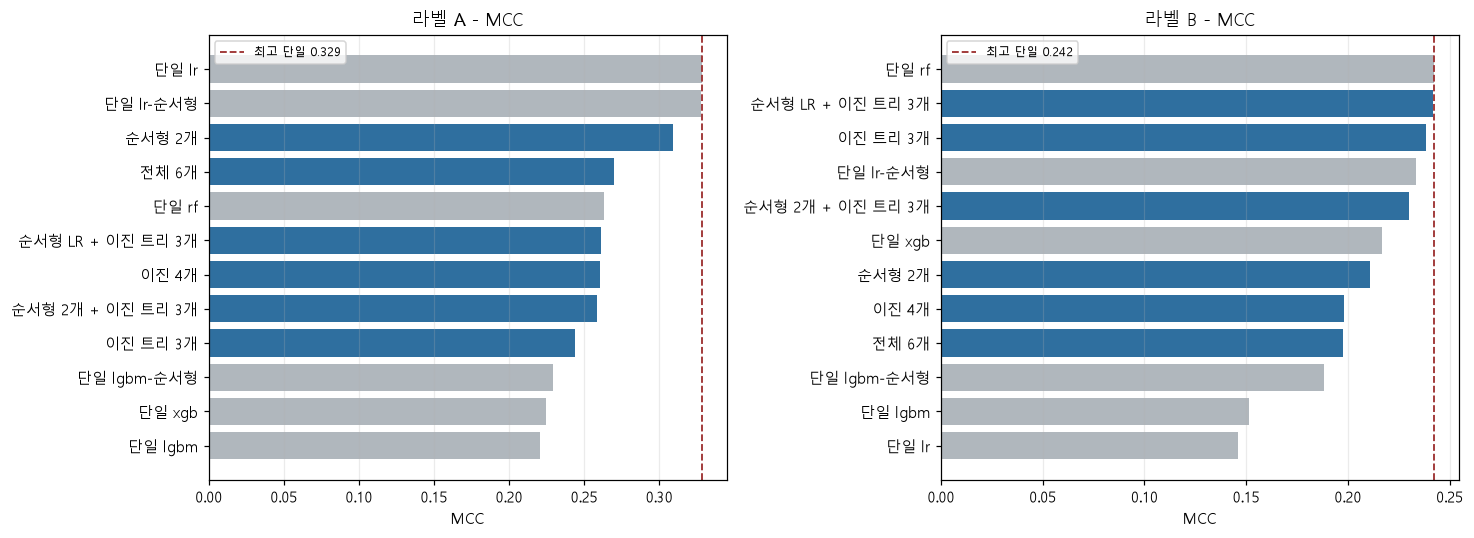

In [27]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties, fontManager
FONT = Path("C:/Windows/Fonts/malgun.ttf")
fontManager.addfont(str(FONT))
plt.rcParams.update({"font.family": FontProperties(fname=FONT).get_name(),
                     "axes.unicode_minus": False, "figure.dpi": 110})

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
for ax, lab in zip(axes, ("A", "B")):
    s = mean10.loc[lab].sort_values("MCC")
    colours = ["#2f6f9f" if not i.startswith("단일") else "#b0b7bd" for i in s.index]
    ax.barh(s.index, s["MCC"], color=colours)
    best_single = s[s.index.str.startswith("단일")]["MCC"].max()
    ax.axvline(best_single, color="#9c3030", ls="--", lw=1.2,
               label=f"최고 단일 {best_single:.3f}")
    ax.set(title=f"라벨 {lab} - MCC", xlabel="MCC")
    ax.legend(fontsize=8); ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

In [28]:
print("최고 앙상블 vs 최고 단일 (seed 3개 평균)")
for lab in ("A", "B"):
    s = mean10.loc[lab]
    be = s[~s.index.str.startswith("단일")].sort_values("MCC").iloc[-1]
    bs = s[s.index.str.startswith("단일")].sort_values("MCC").iloc[-1]
    gain = be.MCC - bs.MCC
    verdict = "채택할 만함" if gain > SEED_SD else "seed 변동 이내 - 효과로 보기 어려움"
    print(f"  {lab}: {be.name} {be.MCC:.3f}  vs  {bs.name} {bs.MCC:.3f}  "
          f"({gain:+.3f}) -> {verdict}")

최고 앙상블 vs 최고 단일 (seed 3개 평균)
  A: 순서형 2개 0.309  vs  단일 lr 0.329  (-0.019) -> seed 변동 이내 - 효과로 보기 어려움
  B: 순서형 LR + 이진 트리 3개 0.242  vs  단일 rf 0.242  (-0.001) -> seed 변동 이내 - 효과로 보기 어려움


In [29]:
# 평균이 아니라 seed마다 짝지어 비교합니다. 평균은 한 seed의 운을 숨길 수 있습니다.
c10["종류"] = np.where(c10.구성.str.startswith("단일"), "단일", "앙상블")
print("seed별: 최고 앙상블 vs 최고 단일")
gaps = []
for lab in ("A", "B"):
    for s in sorted(c10.seed.unique()):
        x = c10[(c10.label == lab) & (c10.seed == s)]
        be = x[x.종류 == "앙상블"].sort_values("MCC").iloc[-1]
        bs = x[x.종류 == "단일"].sort_values("MCC").iloc[-1]
        gaps.append(be.MCC - bs.MCC)
        print(f"  {lab} seed {s}: 앙상블 {be.구성:22} {be.MCC:.3f} | "
              f"단일 {bs.구성:14} {bs.MCC:.3f} | 차 {be.MCC - bs.MCC:+.3f}")
print()
print(f"  6번 중 앙상블이 이긴 횟수 {sum(g > 0 for g in gaps)}/6, 평균 차 {np.mean(gaps):+.3f}")

seed별: 최고 앙상블 vs 최고 단일
  A seed 42: 앙상블 순서형 2개                 0.339 | 단일 단일 lr          0.352 | 차 -0.013
  A seed 202: 앙상블 순서형 2개                 0.304 | 단일 단일 lr-순서형      0.309 | 차 -0.005
  A seed 777: 앙상블 순서형 2개                 0.284 | 단일 단일 lr-순서형      0.332 | 차 -0.047
  B seed 42: 앙상블 순서형 2개 + 이진 트리 3개      0.256 | 단일 단일 lr-순서형      0.273 | 차 -0.016
  B seed 202: 앙상블 이진 트리 3개               0.264 | 단일 단일 rf          0.253 | 차 +0.011
  B seed 777: 앙상블 이진 트리 3개               0.261 | 단일 단일 rf          0.254 | 차 +0.007

  6번 중 앙상블이 이긴 횟수 2/6, 평균 차 -0.010


In [30]:
# 앙상블이 점수를 못 올려도 흔들림은 줄일 수 있습니다. 그쪽을 따로 봅니다.
sd = c10.groupby(["label", "종류"]).MCC.std().unstack()
sd["감소"] = (sd["앙상블"] - sd["단일"]).round(3)
display(sd.round(3))
print("음수이면 앙상블이 seed에 덜 흔들린다는 뜻입니다.")

종류,단일,앙상블,감소
label,,,
A,0.051,0.039,-0.012
B,0.053,0.030,-0.022


음수이면 앙상블이 seed에 덜 흔들린다는 뜻입니다.


### 10에서 나온 예상 밖의 결과 - 순서형 LR이 라벨 B에서 크게 앞섭니다

앙상블 자체는 실패했지만, 구성 요소를 들여다보다 다른 것이 보였습니다. 같은 분할에서
**순서형 LR과 이진 LR을 짝지어 비교**하면 라벨 B에서만 차이가 큽니다.

라벨 B는 등급 3과 4 사이에 경계가 있습니다. 이진 LR은 "3 이하인가"만 배우는데,
순서형 LR은 등급 4개를 모두 맞히도록 학습한 뒤 누적확률로 경계를 만듭니다.
등급 구조를 쓰는 쪽이 이 경계에서 유리한 것으로 보입니다.

In [31]:
w10 = c10[c10.구성.isin(["단일 lr", "단일 lr-순서형"])].pivot_table(
    index=["label", "seed"], columns="구성", values="MCC")
w10["차(순서형-이진)"] = w10["단일 lr-순서형"] - w10["단일 lr"]
display(w10.round(3))
for lab in ("A", "B"):
    d = w10.loc[lab, "차(순서형-이진)"]
    flag = "  ★ seed 변동보다 큼" if abs(d.mean()) > SEED_SD else ""
    print(f"  라벨 {lab}: 평균 {d.mean():+.3f} (개선 {int((d > 0).sum())}/{len(d)}){flag}")

구성          단일 lr  단일 lr-순서형  차(순서형-이진)
label seed                             
A     42    0.352      0.342     -0.010
      202   0.305      0.309      0.003
      777   0.328      0.332      0.003
B     42    0.167      0.273      0.105
      202   0.112      0.181      0.069
      777   0.159      0.248      0.088

  라벨 A: 평균 -0.001 (개선 2/3)
  라벨 B: 평균 +0.087 (개선 3/3)  ★ seed 변동보다 큼


**과거 3부 종합입니다. 다른 프로토콜의 production 순위로 사용하지 않습니다.**

## 3부 종합

In [32]:
lines = []
lines.append("【07 표현 결합】")
for lab in ("A", "B"):
    s = d7[d7.label == lab]
    best = piv.loc[lab].sort_values("MCC", ascending=False).index[0]
    lines.append(f"  라벨 {lab}: 기준 대비 dMCC {s.MCC.mean():+.3f} | 세 표현 중 최고 = {best}")

lines.append("\n【08 확률 보정】")
for lab in ("A", "B"):
    sub = w8.loc[lab].loc["svm"]
    for kind in ("Platt", "Isotonic"):
        dm = (sub[("MCC", kind)] - sub[("MCC", "보정 없음")]).mean()
        dsd = (sub[("foldstd_MCC", kind)] - sub[("foldstd_MCC", "보정 없음")]).mean()
        lines.append(f"  라벨 {lab} svm {kind}: dMCC {dm:+.3f}, fold변동 {dsd:+.3f}")

lines.append("\n【09 분자 표현 계열】 중단 - 결과 없음")

lines.append("\n【10 교차 앙상블】")
for lab in ("A", "B"):
    s = mean10.loc[lab]
    be = s[~s.index.str.startswith("단일")].sort_values("MCC").iloc[-1]
    bs = s[s.index.str.startswith("단일")].sort_values("MCC").iloc[-1]
    lines.append(f"  라벨 {lab}: {be.name} {be.MCC:.3f} vs 최고 단일 {bs.MCC:.3f} "
                 f"({be.MCC - bs.MCC:+.3f})")

lines.append(f"\n판단 기준: seed 변동 표준편차 {SEED_SD} (2부 실험 03에서 측정)")
print("\n".join(lines))

【07 표현 결합】
  라벨 A: 기준 대비 dMCC +0.014 | 세 표현 중 최고 = ③ 결합
  라벨 B: 기준 대비 dMCC +0.024 | 세 표현 중 최고 = ③ 결합

【08 확률 보정】
  라벨 A svm Platt: dMCC -0.009, fold변동 +0.000
  라벨 A svm Isotonic: dMCC -0.005, fold변동 -0.007
  라벨 B svm Platt: dMCC +0.000, fold변동 +0.000
  라벨 B svm Isotonic: dMCC -0.013, fold변동 +0.010

【09 분자 표현 계열】 중단 - 결과 없음

【10 교차 앙상블】
  라벨 A: 순서형 2개 0.309 vs 최고 단일 0.329 (-0.019)
  라벨 B: 순서형 LR + 이진 트리 3개 0.242 vs 최고 단일 0.242 (-0.001)

판단 기준: seed 변동 표준편차 0.024 (2부 실험 03에서 측정)


### 3부의 한계

- 2부와 동일하게 후보 격자를 20개 중 6개만 썼습니다. 절대 수치를 발표된 production
  결과와 비교하면 안 됩니다.
- 07은 seed 2개, 08과 10은 seed 3개입니다. 표준편차는 신뢰구간이 아니며
  통계적 유의성을 주장하지 않습니다.
- 10의 순위 평균 앙상블은 적합되는 파라미터가 없어 pooled AUC가 편향되지 않지만,
  구성(어떤 모델을 섞을지)을 결과를 보고 고르면 그 선택 자체가 낙관적일 수 있습니다.
- 모두 내부 교차검증 결과이며 외부 독립 데이터 검증이 아닙니다.

**과거 실험 11 기록 — 5모델·2seed·축소 격자이며, 5부의 production 결과와 구분합니다.**

---
# 4부 — 실험 11: 농도 복원 (Claude)

3부까지의 결론은 "무엇을 해도 MCC가 안 움직인다"였습니다. 표현을 바꿔도, 확률을 보정해도,
순서형과 이진을 섞어도 전부 seed 변동(±0.024) 안이었습니다.

4부는 **모델이 아니라 입력을 고칩니다.**

## 문제

production 데이터를 해시로 검사하다 찾았습니다. 평가 606행 중 **217행이 "완전히 같은
2265차원 입력인데 정답이 다른" 상태**입니다. 원인은 농도 가중 평균의 약분입니다.

단일성분 제형에서 가중 평균을 내면 농도가 수학적으로 사라집니다.

$$\frac{p \cdot \mathbf{v}}{p} = \mathbf{v}$$

그래서 같은 물질을 0.05%로 쓴 제형과 98%로 쓴 제형이 **모델에게 똑같은 입력**이 됩니다.
실제로 CASRN 82657-04-3은 19개 제형이 0.05%~98%에 걸쳐 있는데 전부 동일한 벡터이고,
정답은 등급 3과 4로 갈립니다. 어떤 모델도 이 행들을 구분할 수 없습니다.

충돌 217행 중 97.7%가 단일성분입니다. 그리고 **농도 값은 CSV에 이미 있습니다**
(`known_pct` 컬럼). feature 열(`fp_`, `desc_`)이 아니라서 모델에 전달되지 않았을 뿐입니다.

## 검증한 두 가지 방안

| 팔 | 방법 | 피처 수 |
|---|---|---|
| ① 기준 | 현재 그대로 | 2,265 |
| ② 농도 피처 추가 | 벡터는 두고 농도 4개를 덧붙임 | 2,269 |
| ③ 희석 스케일링 | 정규화를 빼서 희석을 벡터에 반영 | 2,265 |
| ④ 둘 다 | ② + ③ | 2,269 |

**③의 구현 요령**: 현재 벡터가 $\sum p_i v_i / \sum p_i$ 이므로

$$\sum \frac{p_i}{100} v_i = \frac{\sum p_i}{100} \times \text{현재 벡터}$$

즉 행마다 `pct_sum_used/100`을 곱하기만 하면 됩니다. featurization을 다시 돌릴 필요가
없어서 673행 전부에 적용되고, 기존 결과와도 비교 가능합니다.

> 프로토콜은 2·3부와 같습니다. 완전일치벡터 병합 그룹화, 축소 격자(20개 중 6개),
> 외부 5-fold × 내부 3-fold, seed 42/202. **et는 뺐습니다** - 비용이 가장 큰데
> 지금까지 한 번도 이긴 적이 없습니다. 기준 팔은 2부 실험 03의 결과를 재사용합니다
> (같은 분할, 같은 격자이므로 다시 돌릴 이유가 없습니다).

In [33]:
# 3부 설정 셀을 먼저 실행했다면 adv/advmeta/SEED_SD가 이미 있습니다.
if "adv" not in dir():
    import json, sys
    from pathlib import Path
    import numpy as np, pandas as pd
    CLAUDE = next(p for p in (Path.cwd() / "claude", Path.cwd())
                  if (p / "advanced_utils.py").exists())
    RESULTS = CLAUDE / "results"
    def adv(name):
        return pd.DataFrame(json.loads((RESULTS / f"{name}.json").read_text(encoding="utf-8")))
    def advmeta(name):
        return json.loads((RESULTS / f"{name}.json").read_text(encoding="utf-8"))
    def frame(name):
        return adv(name)
    SEED_SD = 0.024

SEEDS11 = [42, 202]
MODELS11 = ["lr", "svm", "rf", "lgbm", "xgb"]
ARMS = ["① 기준", "② 농도 피처 추가", "③ 희석 스케일링", "④ 농도 피처 + 희석"]

c11 = adv("11_concentration")
base11 = frame("03_grouping_fix_v1")  # 11 remains a first-edition experiment.
base11 = base11[(base11.grouping == "완전일치벡터 병합")
                & (base11.seed.isin(SEEDS11))
                & (base11.model.isin(MODELS11))].copy()
base11["표현"] = "① 기준"
keep = ["label", "seed", "model", "표현", "MCC", "ROC-AUC",
        "sensitivity", "specificity", "foldstd_MCC"]
t11 = pd.concat([base11[keep], c11[keep]], ignore_index=True)
print(f"기준 {len(base11)}칸 + 신규 {len(c11)}칸 = {len(t11)}칸")

기준 20칸 + 신규 60칸 = 80칸


## 11-1. 먼저 - 중복이 실제로 깨지는가

학습을 돌리기 전에 확인할 것이 있습니다. 두 방안이 **정말로 같은 입력을 갈라놓는지**
행렬을 직접 만들어 해시로 세어 봤습니다. 안 깨지면 돌릴 이유가 없습니다.

In [34]:
meta11 = advmeta("11_meta")
chk = pd.DataFrame(meta11["duplicate_check"], index=["완전중복 행", "라벨충돌 행"]).T
chk["해소율"] = (1 - chk["라벨충돌 행"] / chk.loc["① 기준", "라벨충돌 행"]).map("{:.0%}".format)
display(chk)
print(f"피처 수: {meta11['arms']}")
print(f"농도 범위 {meta11['pct_range'][0]}% ~ {meta11['pct_range'][1]}%")
print(f"희석 계수 범위 {meta11['scale_range'][0]} ~ {meta11['scale_range'][1]}"
      "   <- 다섯 자릿수. 선형 모델에 무슨 일이 생길지 여기서 짐작됩니다.")

,완전중복 행,라벨충돌 행,해소율
① 기준,331,221,0%
② 농도 피처 추가,70,18,92%
③ 희석 스케일링,78,18,92%
④ 농도 피처 + 희석,68,18,92%


피처 수: {'② 농도 피처 추가': 2269, '③ 희석 스케일링': 2265, '④ 농도 피처 + 희석': 2269}
농도 범위 0.001% ~ 100.0%
희석 계수 범위 1e-05 ~ 1.0   <- 다섯 자릿수. 선형 모델에 무슨 일이 생길지 여기서 짐작됩니다.


**221행 → 18행. 92%가 해소됩니다.** 그리고 세 방안이 전부 18행으로 똑같습니다.

남은 18행은 농도까지 같은데 정답이 다른 경우라, 어떤 방법으로도 못 고칩니다.
비공개 부형제나 시험 조건의 차이일 것입니다.

여기서 이미 하나가 판정됩니다 - **방안 2는 중복 해소 측면에서 방안 1보다 나을 것이
없습니다.** 그렇다면 남은 질문은 "그래도 학습에는 더 좋은가"입니다.

In [35]:
piv11 = t11.pivot_table(index=["label", "model"], columns="표현", values="MCC")[ARMS]
display(piv11.round(3))
print("라벨 평균")
for metric in ("MCC", "ROC-AUC", "foldstd_MCC"):
    print(f"  --- {metric} ---")
    display(t11.groupby(["label", "표현"])[metric].mean().unstack()[ARMS].round(3))

표현            ① 기준  ② 농도 피처 추가  ③ 희석 스케일링  ④ 농도 피처 + 희석
label model                                            
A     lgbm   0.227       0.244      0.231         0.243
      lr     0.329       0.331      0.133         0.128
      rf     0.267       0.261      0.289         0.273
      svm    0.196       0.194      0.141         0.168
      xgb    0.226       0.251      0.246         0.236
B     lgbm   0.141       0.241      0.227         0.264
      lr     0.140       0.151      0.192         0.180
      rf     0.237       0.259      0.239         0.233
      svm    0.060       0.064      0.099         0.084
      xgb    0.225       0.237      0.223         0.231

라벨 평균
  --- MCC ---


표현,① 기준,② 농도 피처 추가,③ 희석 스케일링,④ 농도 피처 + 희석
label,,,,
A,0.249,0.256,0.208,0.210
B,0.161,0.190,0.196,0.198


  --- ROC-AUC ---


표현,① 기준,② 농도 피처 추가,③ 희석 스케일링,④ 농도 피처 + 희석
label,,,,
A,0.693,0.699,0.682,0.691
B,0.603,0.614,0.629,0.632


  --- foldstd_MCC ---


표현,① 기준,② 농도 피처 추가,③ 희석 스케일링,④ 농도 피처 + 희석
label,,,,
A,0.120,0.106,0.100,0.098
B,0.101,0.085,0.095,0.079


**아래 '채택'은 당시 탐색 판단입니다. 최신 결과에 근거한 채택·배포 확정이 아닙니다.**

## 11-2. 방안 1 (농도 피처) - 채택

평균만 보면 한두 칸의 운에 끌려갈 수 있으므로 **seed와 모델마다 짝지어** 비교합니다.
라벨당 5개 모델 × 2개 seed = 10칸입니다.

In [36]:
w11 = t11.pivot_table(index=["label", "model", "seed"], columns="표현", values="MCC")

def paired(a, b, title):
    print(title)
    for lab in ("A", "B"):
        d = (w11.loc[lab][a] - w11.loc[lab][b]).dropna()
        flag = "   ★ seed 변동 초과" if abs(d.mean()) > SEED_SD else ""
        print(f"    라벨 {lab}: 평균 {d.mean():+.3f}  개선 {int((d > 0).sum())}/{len(d)}"
              f"  최악 {d.min():+.3f}  최고 {d.max():+.3f}{flag}")

paired("② 농도 피처 추가", "① 기준", "방안 1: 농도 피처 추가")
print()
paired("③ 희석 스케일링", "① 기준", "방안 2: 희석 스케일링")
print()
paired("③ 희석 스케일링", "② 농도 피처 추가", "방안 2 vs 방안 1 (직접 비교)")
print()
paired("④ 농도 피처 + 희석", "② 농도 피처 추가", "방안 1+2 vs 방안 1")

방안 1: 농도 피처 추가
    라벨 A: 평균 +0.007  개선 5/10  최악 -0.010  최고 +0.025
    라벨 B: 평균 +0.030  개선 9/10  최악 -0.033  최고 +0.131   ★ seed 변동 초과

방안 2: 희석 스케일링
    라벨 A: 평균 -0.041  개선 4/10  최악 -0.230  최고 +0.049   ★ seed 변동 초과
    라벨 B: 평균 +0.035  개선 7/10  최악 -0.012  최고 +0.177   ★ seed 변동 초과

방안 2 vs 방안 1 (직접 비교)
    라벨 A: 평균 -0.048  개선 3/10  최악 -0.236  최고 +0.040   ★ seed 변동 초과
    라벨 B: 평균 +0.006  개선 4/10  최악 -0.076  최고 +0.109

방안 1+2 vs 방안 1
    라벨 A: 평균 -0.046  개선 4/10  최악 -0.213  최고 +0.021   ★ seed 변동 초과
    라벨 B: 평균 +0.008  개선 5/10  최악 -0.045  최고 +0.091


In [37]:
# 라벨 B에서 어느 모델이 농도를 쓰는가
d = (w11["② 농도 피처 추가"] - w11["① 기준"]).groupby(level=["label", "model"]).mean()
display(d.unstack("label").round(3).rename(columns=lambda c: f"라벨 {c} dMCC")
        .sort_values("라벨 B dMCC", ascending=False))
print("트리 계열(lgbm/rf/xgb)이 농도를 씁니다. 농도와 등급이 단조롭지 않아")
print("선형 모델은 거의 쓰지 못하고, 분기로 구간을 나눌 수 있는 트리가 가져갑니다.")

label,라벨 A dMCC,라벨 B dMCC
model,,
lgbm,0.018,0.100
rf,-0.006,0.022
xgb,0.025,0.013
lr,0.002,0.011
svm,-0.003,0.004


트리 계열(lgbm/rf/xgb)이 농도를 씁니다. 농도와 등급이 단조롭지 않아
선형 모델은 거의 쓰지 못하고, 분기로 구간을 나눌 수 있는 트리가 가져갑니다.


라벨 A에서 효과가 없는 것도 설명이 됩니다. A의 경계는 등급 2와 3 사이인데,
충돌 217행의 등급은 대부분 3과 4입니다. **충돌이 B의 경계에 몰려 있어서**
A는 애초에 이 문제의 영향을 덜 받고 있었습니다.

## 11-3. 방안 2 (희석 스케일링) - 기각

라벨 A에서 무너집니다. 범인은 선형 모델입니다.

In [38]:
lin = piv11.loc["A"].loc[["lr", "svm", "rf"], ["① 기준", "③ 희석 스케일링"]].copy()
lin["차"] = (lin["③ 희석 스케일링"] - lin["① 기준"]).round(3)
display(lin.round(3))
lo, hi = meta11["scale_range"]
print(f"희석 계수가 {lo} ~ {hi}, 다섯 자릿수에 걸쳐 있습니다.")
print("행마다 벡터 전체를 이만큼 다른 배율로 곱하면 열 단위 표준화로는 복구되지 않습니다.")
print("희석 0.001%짜리 행은 벡터가 거의 0이 되어, LR 입장에서는 원점 근처에 뭉친")
print("점 덩어리가 됩니다. 저희 최고 모델이 거기서 주저앉습니다.")

표현,① 기준,③ 희석 스케일링,차
model,,,
lr,0.329,0.133,-0.196
svm,0.196,0.141,-0.056
rf,0.267,0.289,0.022


희석 계수가 1e-05 ~ 1.0, 다섯 자릿수에 걸쳐 있습니다.
행마다 벡터 전체를 이만큼 다른 배율로 곱하면 열 단위 표준화로는 복구되지 않습니다.
희석 0.001%짜리 행은 벡터가 거의 0이 되어, LR 입장에서는 원점 근처에 뭉친
점 덩어리가 됩니다. 저희 최고 모델이 거기서 주저앉습니다.


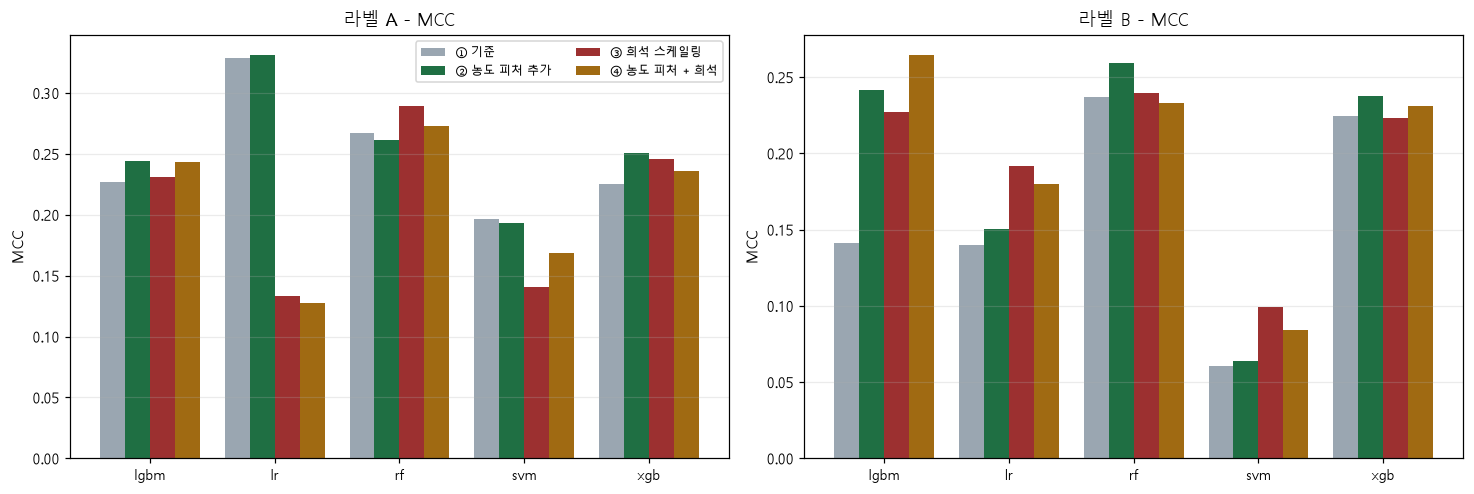

In [39]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties, fontManager
FONT = Path("C:/Windows/Fonts/malgun.ttf")
fontManager.addfont(str(FONT))
plt.rcParams.update({"font.family": FontProperties(fname=FONT).get_name(),
                     "axes.unicode_minus": False, "figure.dpi": 110})

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
for ax, lab in zip(axes, ("A", "B")):
    sub = piv11.loc[lab]
    x = np.arange(len(sub))
    width = 0.2
    for i, arm in enumerate(ARMS):
        colour = ["#9aa6b1", "#1f6f43", "#9c3030", "#a06a12"][i]
        ax.bar(x + (i - 1.5) * width, sub[arm], width, label=arm, color=colour)
    ax.set_xticks(x); ax.set_xticklabels(sub.index, fontsize=9)
    ax.set(title=f"라벨 {lab} - MCC", ylabel="MCC")
    ax.grid(axis="y", alpha=0.25)
    if lab == "A":
        ax.legend(fontsize=8, ncol=2)
plt.tight_layout()

**과거 4부 결론을 보존한 절입니다. 현재 결론은 6부가 우선합니다.**

## 4부 결론

In [40]:
lines = []
lines.append("【중복 해소】")
for arm in ARMS:
    n = meta11["duplicate_check"][arm][1]
    lines.append(f"  {arm:16} 라벨충돌 {n:3}행")
lines.append("  -> 세 방안 모두 221행에서 18행으로. 방안 2에 추가 이득 없음.")

lines.append("")
lines.append("【학습 결과, 기준 대비 짝지은 평균 dMCC】")
for arm in ARMS[1:]:
    row = []
    for lab in ("A", "B"):
        d = (w11.loc[lab][arm] - w11.loc[lab]["① 기준"]).dropna()
        mark = "★" if abs(d.mean()) > SEED_SD else " "
        row.append(f"{lab} {d.mean():+.3f}{mark} ({int((d > 0).sum())}/{len(d)})")
    lines.append(f"  {arm:16} " + "   ".join(row))

lines.append("")
lines.append("【라벨별 최고】")
best = t11.groupby(["label", "표현", "model"]).MCC.mean().reset_index()
for lab in ("A", "B"):
    b0 = best[(best.label == lab) & (best.표현 == "① 기준")].MCC.max()
    top = best[best.label == lab].sort_values("MCC").iloc[-1]
    lines.append(f"  라벨 {lab}: 기준 최고 {b0:.3f}  ->  "
                 f"{top.표현} {top.model} {top.MCC:.3f} ({top.MCC - b0:+.3f})")

lines.append("")
lines.append("【판정】")
lines.append("  방안 1 (농도 피처)   채택  - B에서 seed 변동 초과, A에 무해, fold 변동 감소")
lines.append("  방안 2 (희석 스케일) 기각  - A에서 선형 모델 붕괴, B에서도 방안 1보다 못함")
lines.append("  방안 1+2             기각  - 방안 1 대비 이득 없음")
lines.append("")
lines.append(f"판단 기준: seed 변동 표준편차 {SEED_SD}")
print("\n".join(lines))

【중복 해소】
  ① 기준             라벨충돌 221행
  ② 농도 피처 추가       라벨충돌  18행
  ③ 희석 스케일링        라벨충돌  18행
  ④ 농도 피처 + 희석     라벨충돌  18행
  -> 세 방안 모두 221행에서 18행으로. 방안 2에 추가 이득 없음.

【학습 결과, 기준 대비 짝지은 평균 dMCC】
  ② 농도 피처 추가       A +0.007  (5/10)   B +0.030★ (9/10)
  ③ 희석 스케일링        A -0.041★ (4/10)   B +0.035★ (7/10)
  ④ 농도 피처 + 희석     A -0.039★ (4/10)   B +0.038★ (8/10)

【라벨별 최고】
  라벨 A: 기준 최고 0.329  ->  ② 농도 피처 추가 lr 0.331 (+0.002)
  라벨 B: 기준 최고 0.237  ->  ④ 농도 피처 + 희석 lgbm 0.264 (+0.027)

【판정】
  방안 1 (농도 피처)   채택  - B에서 seed 변동 초과, A에 무해, fold 변동 감소
  방안 2 (희석 스케일) 기각  - A에서 선형 모델 붕괴, B에서도 방안 1보다 못함
  방안 1+2             기각  - 방안 1 대비 이득 없음

판단 기준: seed 변동 표준편차 0.024


**아래 해석·최고점·다음 작업은 과거 기록입니다. 최신 검증 완료 상태와 결론은 5~6부를 확인하세요.**

### 무엇이 달라졌나

지금까지 돌린 모든 실험 - 앙상블, 순서형, 표현 결합, 확률 보정, 최악성분 pooling -
가운데 **처음으로 seed 변동을 넘긴 개선**입니다. 그리고 그것은 모델을 바꿔서가 아니라
**입력에 없던 정보를 넣어서** 얻었습니다.

2부와 3부가 전부 제자리였던 이유가 이것으로 설명됩니다. 평가 606행 중 217행의 입력이
동일했으니, 어떤 모델도 그 행들을 구분할 수 없었습니다. 모델링 기법으로는 애초에
닿을 수 없는 문제였습니다.

### 솔직한 평가 - 기대만큼은 아닙니다

입력 그룹을 다수결로 맞힌다고 가정한 이론적 천장은 라벨 A 0.840 → 0.984,
B 0.787 → 0.982로 올라갑니다. 그런데 실측은 B 0.237 → 0.264입니다.

**천장이 열렸다고 모델이 거기까지 가는 것은 아닙니다.** 농도와 등급의 관계가
단조롭지 않습니다 - 같은 물질이 25.1%에서 등급 4인데 98%에서 등급 3입니다.
673행으로 그런 함수를 배우기는 어렵습니다.

### 4부의 한계

- seed가 2개뿐입니다(2·3부의 08·10은 3개). 짝지은 비교로 보완했지만
  신뢰구간이 아니며 통계적 유의성을 주장하지 않습니다.
- et를 뺐으므로 2·3부의 6모델 표와 절대 수치를 나란히 두면 안 됩니다.
- 라벨 B 최고 0.264는 ④(둘 다)에서 나왔지만, ④는 방안 1 대비 평균 +0.008로
  잡음 수준이고 10칸 중 한 칸입니다. **여러 조합 중 최고를 사후에 고르면 낙관적으로
  나옵니다.** 안전한 선택은 ② 단독입니다.
- 축소 격자(20개 중 6개)이므로 발표된 production 수치와 비교하면 안 됩니다.
- 내부 교차검증 결과이며 외부 독립 데이터 검증이 아닙니다.

### 다음

같은 방향으로 더 갈 수 있습니다.

| 할 일 | 근거 |
|---|---|
| `test_concentration`을 원본에서 복구 | 현재 673행 전부 결측. 시험 농도는 자극성의 직접 결정 인자 |
| 비공개 부형제(`undeclared_pct`) 세분 | 지금은 비율 하나뿐. 어떤 부형제인지가 남은 18행의 열쇠일 수 있음 |
| 농도 x 물성 교호작용 항 | 비단조 관계를 트리에만 맡기지 말고 명시적으로 제공 |

---
# 5부 — 농도 production 검증 (완료)

기존 결과 identity: `f91f3c88787bec6be1bef4bbbfcb98b797e0d69c6fda8c9bd03d508661488f4b`.
학습은 2026-11-08에 완료됐으며 아래 표는 그 결과의 재집계입니다.

| 항목 | 이번 production 규약 |
|---|---|
| 입력/평가 | 673행 중 기존 **606행만 평가**, 증강 67행은 train-only |
| 그룹 | comp/split 연결 및 원본 fp/desc의 소수 6자리 반올림 중복을 병합 |
| 증강 제외 | outer test 또는 inner validation 그룹과 연결된 증강은 해당 학습에서 제외 |
| 비교 | baseline 2265개 vs 농도 피처 4개 추가 2269개; 원본 벡터 재스케일 없음 |
| 모델/seed | LR, RF, ExtraTrees, SVM, XGBoost, LightGBM × 42/202/777 |
| 검증 | outer 5-fold × inner 3-fold, 각 모델 **20후보 전체 격자**; inner 평균 AUC로 선택 |
| threshold | 기존행 inner OOF에서 민감도–특이도 차 최소화, MCC·작은 threshold 순으로 동률 해소 |
| 작업 수 | 2 arm × 2 label × 6 model × 3 seed × 5 fold = **360 outer** |
| 지표 집계 | seed별 5개 outer 예측을 합친 606행 OOF에서 계산 → 3seed 평균 ± 표본 표준편차 |
| 라벨 | A: EPA I/II 양성, B: EPA I/II/III 양성 |

농도는 `known_pct → pct_sum_used → 해당 학습 fold 중앙값` 순으로 보완합니다.
피처는 `log10(pct+0.001)`, `pct/100`, `pct>=90`, `undeclared_pct/100`이며
`undeclared_pct` 결측은 0입니다. validation/test로 중앙값을 다시 계산하지 않습니다.

## 5-1. 결과 checksum 및 실제 outer 예측 확인

아래 셀은 저장된 JSON을 검증하고 OOF 지표를 재계산합니다. 학습 실행기를 호출하지 않습니다.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

PROD_ID = "f91f3c88787bec6be1bef4bbbfcb98b797e0d69c6fda8c9bd03d508661488f4b"

def prod_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def prod_hash_json(payload):
    return hashlib.sha256(json.dumps(payload, ensure_ascii=False, sort_keys=True,
                                    separators=(",", ":"), allow_nan=False).encode("utf-8")).hexdigest()

def prod_record(path):
    record = json.loads(Path(path).read_text(encoding="utf-8"))
    assert record["identity"] == PROD_ID, f"다른 실험 identity: {path}"
    assert record["payload_sha256"] == prod_hash_json(record["payload"]), f"checksum 오류: {path}"
    return record["payload"]

# notebook 폴더 또는 repository의 최종/ 폴더에서 실행 가능. 개인 절대경로 없음.
prod_candidates = []
for parent in (Path.cwd(), *Path.cwd().parents):
    prod_candidates.extend([parent / "claude", parent,
        parent / "모델 실험/eye/claude", parent / "최종/모델 실험/eye/claude"])
PROD_CLAUDE = next((p for p in prod_candidates
                   if (p / "results/concentration_production" / PROD_ID[:16] / "config.json").exists()), None)
assert PROD_CLAUDE is not None, "claude/results/concentration_production/f91f3c88787bec6b 자료가 필요합니다."
PROD_RUN = PROD_CLAUDE / "results/concentration_production" / PROD_ID[:16]
prod_config = prod_record(PROD_RUN / "config.json")
assert prod_hash_json(prod_config) == PROD_ID
prod_metrics = pd.DataFrame(prod_record(PROD_RUN / "metrics.json"))
prod_paired = pd.DataFrame(prod_record(PROD_RUN / "paired_comparison.json"))
prod_export = prod_record(PROD_RUN / "export_manifest.json")
prod_delivery_path = PROD_CLAUDE / "results/continuation_20261108T111518/delivery_verification.json"
prod_delivery = json.loads(prod_delivery_path.read_text(encoding="utf-8"))
assert prod_delivery["identity"] == PROD_ID
assert prod_delivery["status"] == "delivery_verified"
for name, expected in prod_delivery["final_artifacts_sha256"].items():
    assert prod_sha(PROD_RUN / name) == expected, f"완료 후 파일 변경: {name}"
assert prod_config["input_sha256"] == prod_export["source_sha256"] == prod_delivery["input_eye_sha256"]
assert prod_export["output_sha256"] == prod_sha(PROD_RUN / "eye_vectorized_concentration.csv")
assert prod_export["rows"] == 673 and prod_export["feature_count"] == 2269
assert prod_config["seeds"] == [42, 202, 777]
assert set(prod_config["grids"]) == {"lr", "rf", "et", "svm", "xgb", "lgbm"}
assert all(len(grid) == 20 for grid in prod_config["grids"].values())
assert len(prod_config["features"]["baseline"]) == 2265
assert len(prod_config["features"]["concentration"]) == 2269
print("검증된 run identity:", PROD_ID)
print("Eye 입력 SHA256:", prod_config["input_sha256"])
print("최종 결과 4개 파일의 SHA256 일치. 파생 CSV는 checksum만 확인하며 CV 입력으로 읽지 않습니다.")

검증된 run identity: f91f3c88787bec6be1bef4bbbfcb98b797e0d69c6fda8c9bd03d508661488f4b
Eye 입력 SHA256: 811268d4813fcdd68e85458641bf5823239cae04e1fa871766c77e04f0221e7f
최종 결과 4개 파일의 SHA256 일치. 파생 CSV는 checksum만 확인하며 CV 입력으로 읽지 않습니다.


In [2]:
from sklearn.metrics import matthews_corrcoef, roc_auc_score, confusion_matrix
from itertools import product

prod_groups = np.asarray(prod_config["groups"])
assert len(prod_groups) == 673
prod_evaluation = sorted(i for f in prod_config["splits"]["42"] for i in f["test"])
assert len(prod_evaluation) == len(set(prod_evaluation)) == 606
prod_evaluation_set = set(prod_evaluation)
prod_augmentation = set(range(673)) - prod_evaluation_set
assert len(prod_augmentation) == 67
prod_outer = []
for arm, label, model, seed, fold_number in product(
        ["baseline", "concentration"], ["A", "B"],
        sorted(prod_config["grids"]), prod_config["seeds"], range(5)):
    path = PROD_RUN / arm / label / model / str(seed) / f"fold-{fold_number}" / "outer.json"
    r = prod_record(path)
    assert (r["arm"], r["label"], r["model"], r["seed"], r["fold"]) == (arm, label, model, seed, fold_number)
    f = prod_config["splits"][str(seed)][fold_number]
    assert r["test"] == f["test"] and r["train_rows"] == f["train"]
    assert r["calibration_rows"] == f["calibration"]
    assert r["candidates_evaluated"] == 20 and r["selected_candidate"] in prod_config["grids"][model]
    test, train, calibration = map(set, (f["test"], f["train"], f["calibration"]))
    assert not (test | calibration) & prod_augmentation
    assert not set(prod_groups[f["train"]]) & set(prod_groups[f["test"]])
    assert train & prod_augmentation == {i for i in prod_augmentation if prod_groups[i] not in prod_groups[f["test"]]}
    assert len(f["inner"]) == 3
    inner_coverage = []
    for part in f["inner"]:
        a, b = set(part["train"]), set(part["validation"])
        inner_coverage.extend(part["validation"])
        assert not b & prod_augmentation and a <= train
        blocked_groups = set(prod_groups[sorted(test | b)])
        assert not set(prod_groups[part["train"]]) & blocked_groups
        assert a & prod_augmentation == {i for i in prod_augmentation if prod_groups[i] not in blocked_groups}
    assert sorted(inner_coverage) == sorted(calibration)
    assert np.isfinite(r["threshold"]) and np.isfinite(r["scores"]).all()
    np.testing.assert_array_equal(np.asarray(r["scores"]) >= r["threshold"], r["predictions"])
    assert len(r["test"]) == len(r["y_true"]) == len(r["scores"]) == len(r["predictions"])
    prod_outer.append(r)
assert len(prod_outer) == 360

# 각 seed의 5개 outer fold를 합친 606행 OOF에서 지표를 다시 계산한다.
prod_recomputed = []
prod_outer_frame = pd.DataFrame(prod_outer)
for keys, parts in prod_outer_frame.groupby(["arm", "label", "model", "seed"], sort=True):
    parts = parts.sort_values("fold")
    idx = np.concatenate(parts.test.to_list())
    assert sorted(idx.tolist()) == prod_evaluation
    y = np.concatenate(parts.y_true.to_list())
    scores = np.concatenate(parts.scores.to_list())
    predictions = np.concatenate(parts.predictions.to_list())
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    prod_recomputed.append(dict(zip(["arm", "label", "model", "seed"], keys),
        MCC=matthews_corrcoef(y, predictions), sensitivity=tp/(tp+fn),
        specificity=tn/(tn+fp), **{"ROC-AUC": roc_auc_score(y, scores)}))
prod_recomputed = pd.DataFrame(prod_recomputed)
prod_keys = ["arm", "label", "model", "seed"]
prod_metric_names = ["MCC", "sensitivity", "specificity", "ROC-AUC"]
assert len(prod_metrics) == len(prod_recomputed) == 72
assert not prod_metrics.duplicated(prod_keys).any()
np.testing.assert_allclose(prod_recomputed.set_index(prod_keys).sort_index()[prod_metric_names],
    prod_metrics.set_index(prod_keys).sort_index()[prod_metric_names], rtol=1e-12, atol=1e-12)
prod_check_pairs = prod_metrics.pivot(index=["label", "model", "seed"], columns="arm", values="MCC")
prod_check_pairs["delta_MCC"] = prod_check_pairs.concentration - prod_check_pairs.baseline
assert len(prod_paired) == 36 and not prod_paired.duplicated(["label", "model", "seed"]).any()
np.testing.assert_allclose(prod_check_pairs.sort_index()[["baseline", "concentration", "delta_MCC"]],
    prod_paired.set_index(["label", "model", "seed"]).sort_index()[["baseline", "concentration", "delta_MCC"]],
    rtol=1e-12, atol=1e-12)
print("360개 outer checksum/분할 확인, 72개 OOF × 606행 coverage, 4개 성능지표 재집계 일치")
print("증강행의 outer 평가·inner validation·threshold calibration 포함: 0행")
print("validation/test 연결 그룹의 증강행이 해당 학습에서 제외됨을 확인했습니다.")
print("후보 7,200개 전체 완료는 기존 delivery_verification.json의 검증 기록입니다.")
print("이 절에서는 후보/모델을 학습하지 않았습니다.")

360개 outer checksum/분할 확인, 72개 OOF × 606행 coverage, 4개 성능지표 재집계 일치
증강행의 outer 평가·inner validation·threshold calibration 포함: 0행
validation/test 연결 그룹의 증강행이 해당 학습에서 제외됨을 확인했습니다.
후보 7,200개 전체 완료는 기존 delivery_verification.json의 검증 기록입니다.
이 절에서는 후보/모델을 학습하지 않았습니다.


## 5-2. 라벨·모델별 MCC 차이 및 전체 성능표

`ΔMCC = 농도 추가 − baseline`. 각 칸의 ±는 **3seed 표본 표준편차(ddof=1)**입니다.
짝지은 Δ의 표준편차는 같은 seed의 두 arm 차이로 계산하며 두 arm 표준편차를 더하지 않습니다.
3개 seed는 같은 데이터의 재분할이므로 독립 표본 기반 신뢰구간·유의성 검정으로 해석하지 않습니다.

In [3]:
prod_names = {"lr": "LogisticRegression", "rf": "RandomForest", "et": "ExtraTrees",
              "svm": "SVM", "xgb": "XGBoost", "lgbm": "LightGBM"}
prod_order = ["lr", "rf", "et", "svm", "xgb", "lgbm"]
prod_stats = prod_metrics.groupby(["label", "model", "arm"])[prod_metric_names].agg(["mean", "std"])
prod_delta_stats = prod_paired.groupby(["label", "model"]).delta_MCC.agg(["mean", "std"])
assert prod_metrics.groupby(["label", "model", "arm"]).size().eq(3).all()
prod_mcc_rows = []
for label in ["A", "B"]:
    for model in prod_order:
        b = prod_stats.loc[(label, model, "baseline")]
        c = prod_stats.loc[(label, model, "concentration")]
        delta = prod_delta_stats.loc[(label, model)]
        prod_mcc_rows.append({"라벨": label, "모델": prod_names[model],
            "기준 MCC": f"{b[('MCC','mean')]:.4f} ± {b[('MCC','std')]:.4f}",
            "농도 MCC": f"{c[('MCC','mean')]:.4f} ± {c[('MCC','std')]:.4f}",
            "짝지은 ΔMCC": f"{delta['mean']:+.4f} ± {delta['std']:.4f}"})
display(pd.DataFrame(prod_mcc_rows).style.hide(axis="index"))
print("평균 ± 표본 표준편차(ddof=1), seed 42/202/777의 3개 값. Δ = 농도 − 기준.")
print("fold 평균/표준편차가 아니며, Δ 표준편차는 동일 seed의 차이 3개로 계산합니다.")

for label in ["A", "B"]:
    display(Markdown(f"**라벨 {label}: 4개 성능지표 (평균 ± 표준편차)**"))
    rows = []
    for model in prod_order:
        for arm in ["baseline", "concentration"]:
            stats = prod_stats.loc[(label, model, arm)]
            row = {"모델": prod_names[model], "입력": "기준" if arm == "baseline" else "농도 추가"}
            for key, title in [("MCC", "MCC"), ("sensitivity", "Sensitivity"),
                               ("specificity", "Specificity"), ("ROC-AUC", "ROC-AUC")]:
                row[title] = f"{stats[(key,'mean')]:.4f} ± {stats[(key,'std')]:.4f}"
            rows.append(row)
    display(pd.DataFrame(rows).style.hide(axis="index"))

라벨,모델,기준 MCC,농도 MCC,짝지은 ΔMCC
A,LogisticRegression,0.3361 ± 0.0035,0.3374 ± 0.0012,+0.0013 ± 0.0023
A,RandomForest,0.2749 ± 0.0112,0.2763 ± 0.0183,+0.0014 ± 0.0073
A,ExtraTrees,0.2604 ± 0.0123,0.2520 ± 0.0227,-0.0084 ± 0.0182
A,SVM,0.2402 ± 0.0346,0.2404 ± 0.0390,+0.0002 ± 0.0048
A,XGBoost,0.2371 ± 0.0253,0.2350 ± 0.0275,-0.0021 ± 0.0282
A,LightGBM,0.2115 ± 0.0490,0.2515 ± 0.0375,+0.0399 ± 0.0664
B,LogisticRegression,0.1560 ± 0.0425,0.1604 ± 0.0463,+0.0044 ± 0.0045
B,RandomForest,0.2000 ± 0.0529,0.2151 ± 0.0293,+0.0152 ± 0.0336
B,ExtraTrees,0.1945 ± 0.0293,0.2045 ± 0.0225,+0.0100 ± 0.0335
B,SVM,0.1315 ± 0.0327,0.1315 ± 0.0345,-0.0000 ± 0.0044


평균 ± 표본 표준편차(ddof=1), seed 42/202/777의 3개 값. Δ = 농도 − 기준.
fold 평균/표준편차가 아니며, Δ 표준편차는 동일 seed의 차이 3개로 계산합니다.


**라벨 A: 4개 성능지표 (평균 ± 표준편차)**

모델,입력,MCC,Sensitivity,Specificity,ROC-AUC
LogisticRegression,기준,0.3361 ± 0.0035,0.7101 ± 0.0402,0.7040 ± 0.0313,0.7207 ± 0.0125
LogisticRegression,농도 추가,0.3374 ± 0.0012,0.7101 ± 0.0402,0.7054 ± 0.0324,0.7207 ± 0.0125
RandomForest,기준,0.2749 ± 0.0112,0.6638 ± 0.0219,0.6775 ± 0.0200,0.7192 ± 0.0094
RandomForest,농도 추가,0.2763 ± 0.0183,0.6812 ± 0.0050,0.6640 ± 0.0250,0.7232 ± 0.0071
ExtraTrees,기준,0.2604 ± 0.0123,0.6754 ± 0.0479,0.6511 ± 0.0285,0.7100 ± 0.0276
ExtraTrees,농도 추가,0.2520 ± 0.0227,0.6638 ± 0.0494,0.6517 ± 0.0304,0.7125 ± 0.0219
SVM,기준,0.2402 ± 0.0346,0.6754 ± 0.0905,0.6239 ± 0.1030,0.6532 ± 0.0535
SVM,농도 추가,0.2404 ± 0.0390,0.6725 ± 0.0892,0.6266 ± 0.1059,0.6535 ± 0.0536
XGBoost,기준,0.2371 ± 0.0253,0.7072 ± 0.0351,0.5940 ± 0.0270,0.6834 ± 0.0126
XGBoost,농도 추가,0.2350 ± 0.0275,0.6783 ± 0.0261,0.6185 ± 0.0388,0.7013 ± 0.0274


**라벨 B: 4개 성능지표 (평균 ± 표준편차)**

모델,입력,MCC,Sensitivity,Specificity,ROC-AUC
LogisticRegression,기준,0.1560 ± 0.0425,0.5921 ± 0.0423,0.5699 ± 0.0254,0.5974 ± 0.0066
LogisticRegression,농도 추가,0.1604 ± 0.0463,0.5981 ± 0.0410,0.5684 ± 0.0282,0.5918 ± 0.0160
RandomForest,기준,0.2000 ± 0.0529,0.6247 ± 0.0557,0.5822 ± 0.0116,0.6363 ± 0.0236
RandomForest,농도 추가,0.2151 ± 0.0293,0.6195 ± 0.0404,0.6037 ± 0.0394,0.6427 ± 0.0069
ExtraTrees,기준,0.1945 ± 0.0293,0.6033 ± 0.0300,0.5991 ± 0.0000,0.6326 ± 0.0064
ExtraTrees,농도 추가,0.2045 ± 0.0225,0.6238 ± 0.0275,0.5883 ± 0.0174,0.6316 ± 0.0127
SVM,기준,0.1315 ± 0.0327,0.6127 ± 0.0671,0.5223 ± 0.0372,0.5750 ± 0.0126
SVM,농도 추가,0.1315 ± 0.0345,0.6127 ± 0.0671,0.5223 ± 0.0375,0.5736 ± 0.0142
XGBoost,기준,0.1827 ± 0.0475,0.5955 ± 0.0372,0.5945 ± 0.0302,0.6150 ± 0.0109
XGBoost,농도 추가,0.2239 ± 0.0312,0.6272 ± 0.0271,0.6052 ± 0.0148,0.6348 ± 0.0173


### 농도 추가의 변화량

오차 막대는 짝지은 ΔMCC의 seed 표준편차입니다. 신뢰구간이나 통계적 동등성 판정이 아닙니다.
기존 탐색에서 사용한 공통 ±0.024 기준을 이번 결과의 채택 기준으로 옮기지 않습니다.

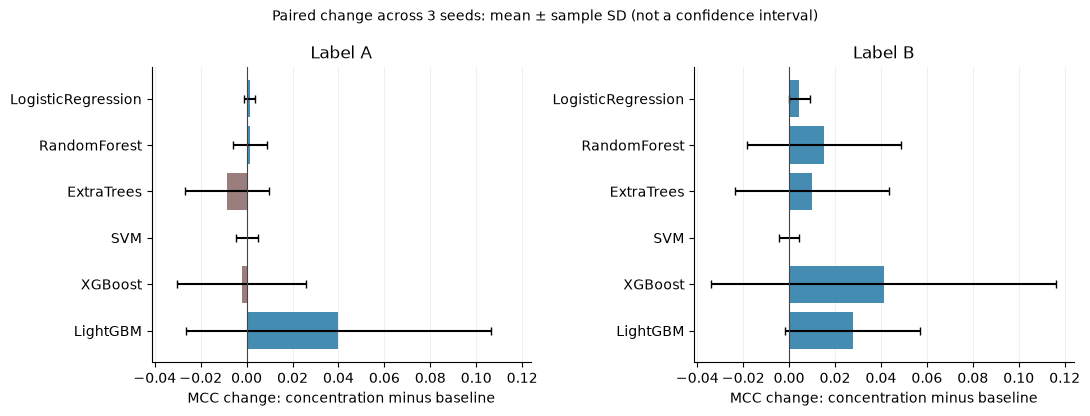

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, label in zip(axes, ["A", "B"]):
    frame = prod_delta_stats.loc[label].reindex(prod_order)
    values, deviations = frame["mean"].to_numpy(), frame["std"].to_numpy()
    ax.barh(range(6), values, xerr=deviations, capsize=3,
            color=["#2478a5" if value >= 0 else "#8a6666" for value in values], alpha=0.85)
    ax.set_yticks(range(6), [prod_names[m] for m in prod_order])
    ax.invert_yaxis()
    ax.axvline(0, color="#444444", linewidth=0.8)
    ax.set_title(f"Label {label}")
    ax.set_xlabel("MCC change: concentration minus baseline")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Paired change across 3 seeds: mean ± sample SD (not a confidence interval)", fontsize=10)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5-3. 그룹화 결과와 파이프라인 검증 상태

그룹화 실험03은 **673행 CV**로 별도 연구입니다. 00~02 및 04~11의 과거 캐시를
2판 그룹화로 재계산한 것처럼 해석하지 않으며, historical 비교 기준은 `03_grouping_fix_v1.json`입니다.

전체 성능 검증 완료와 코드 테스트 통과는 서로 다른 근거입니다. 아래에서는 두 상태를 구분합니다.

In [5]:
prod_grouping_path = PROD_CLAUDE / "results/03_grouping_fix_edition_comparison.csv"
prod_grouping = pd.read_csv(prod_grouping_path)
prod_verdict = json.loads((PROD_CLAUDE / "results/03_grouping_fix_verdict.json").read_text(encoding="utf-8"))
assert np.isclose(prod_grouping.query("edition == 'v2' and label == 'ALL'").delta_MCC.iloc[0], prod_verdict["delta_MCC"])
display(prod_grouping.pivot(index="label", columns="edition", values="delta_MCC").rename(
    columns={"v1": "1판 ΔMCC", "v2": "2판 ΔMCC"}).style.format("{:+.6f}"))
print("그룹화 2판 판정:", prod_verdict["decision"])
print("이 표는 증강까지 평가에 포함한 673행 실험입니다. production 606행 결과와 섞지 않습니다.")

prod_pipeline_path = PROD_CLAUDE / "results/pipeline_v2_20261108T144904/delivery_manifest.json"
prod_pipeline = json.loads(prod_pipeline_path.read_text(encoding="utf-8"))
assert prod_pipeline["original_evaluation_identity"] == PROD_ID
assert prod_pipeline["regression_tests_passed"] == 28
assert prod_sha(prod_pipeline_path.parent / "regression_tests.log") == prod_pipeline["regression_log_sha256"]
assert prod_sha(prod_pipeline_path.parent / "integration/verification.json") == prod_pipeline["integration_report_sha256"]
for name, expected in prod_pipeline["v2_code_sha256"].items():
    assert prod_sha(PROD_CLAUDE / name) == expected, f"pipeline 검증 이후 변경된 파일: {name}"
assert not prod_pipeline["production_model_deployed_or_replaced"]
display(pd.DataFrame([
    {"구분": "전체 성능 검증", "확인 내용": "360 outer / 72 OOF 세트 / 기존 606행; 기존 완료 결과 재집계"},
    {"구분": "코드 기능 검증", "확인 내용": "28개 테스트; LR 두 arm 각 121행의 기존 결과·저장·별도 CLI 예측 일치"},
    {"구분": "최종 모델 학습·배포", "확인 내용": "전체 673행 최종 후보 학습 및 배포·교체 미실행"},
]).style.hide(axis="index"))
prod_notebook_validation = {
    "identity": PROD_ID, "outer_records_verified": len(prod_outer),
    "oof_sets_verified": len(prod_recomputed), "rows_per_oof_set": len(prod_evaluation),
    "augmentation_evaluated": 0, "heldout_group_leakage": False,
    "recomputed_metrics_match": True, "paired_deltas_match": True,
    "pipeline_tests_previously_passed": 28,
    "new_model_fits": 0, "new_full_cv_performed": False,
}
print("NOTEBOOK_VALIDATION_JSON=" + json.dumps(prod_notebook_validation, ensure_ascii=False, sort_keys=True))

edition,1판 ΔMCC,2판 ΔMCC
label,,
A,+0.000925,-0.009772
ALL,-0.007519,-0.014205
B,-0.015964,-0.018638


그룹화 2판 판정: 중간 구간: 제공된 기준으로 확정 불가
이 표는 증강까지 평가에 포함한 673행 실험입니다. production 606행 결과와 섞지 않습니다.


구분,확인 내용
전체 성능 검증,360 outer / 72 OOF 세트 / 기존 606행; 기존 완료 결과 재집계
코드 기능 검증,28개 테스트; LR 두 arm 각 121행의 기존 결과·저장·별도 CLI 예측 일치
최종 모델 학습·배포,전체 673행 최종 후보 학습 및 배포·교체 미실행


NOTEBOOK_VALIDATION_JSON={"augmentation_evaluated": 0, "heldout_group_leakage": false, "identity": "f91f3c88787bec6be1bef4bbbfcb98b797e0d69c6fda8c9bd03d508661488f4b", "new_full_cv_performed": false, "new_model_fits": 0, "oof_sets_verified": 72, "outer_records_verified": 360, "paired_deltas_match": true, "pipeline_tests_previously_passed": 28, "recomputed_metrics_match": true, "rows_per_oof_set": 606}


---
# 6부 — 갱신된 종합 결론

**현재 성능 판단은 5부의 606행 production 검증을 기준으로 합니다.**
1~4부는 모델·표현을 탐색했던 과거 기록이며 같은 프로토콜로 모두 재검증된 결과가 아닙니다.

1. **라벨 A:** 평균 MCC가 가장 높은 모델은 두 arm 모두 LR입니다.
   baseline **0.336051 → 농도 추가 0.337392**,
   짝지은 변화는 **+0.001342 ± 0.002324**입니다.
   개선 폭이 작으므로 농도 피처가 A 성능을 크게 올렸다고 결론내리지 않습니다.
2. **라벨 B:** 농도 추가 XGBoost의 평균 MCC는 **0.223927**로
   비교한 조합 중 가장 높습니다. 같은 모델 baseline 대비 변화는
   **+0.041270 ± 0.075155**로 seed 변동이 큽니다.
   농도 RF **0.215147**, 농도 LightGBM
   **0.211707**도 비교 후보로 남습니다.
   평균 순위만으로 XGBoost의 우월성이나 최종 채택을 확정하지 않습니다.
3. **농도 피처의 해석:** 효과는 라벨·모델에 따라 다릅니다. 과거 실험11의
   'B에서 seed 변동 초과, A에 무해 → 채택' 문구를 이번 검증의 종합 결론으로 유지하지 않습니다.
   원래 fp/desc를 농도로 재스케일하는 희석 실험은 이번 production의 비교 대상이 아닙니다.
4. **그룹화:** 2판 전체 ΔMCC는 **−0.014205**입니다. 지정 기준에서 중간 구간이므로
   '걱정은 기우' 또는 '영향 없음'으로 확정하지 않습니다. 이 실험은 증강까지 평가한
   673행 CV이며 production 결과와 분리해 해석합니다.
5. **적용 상태:** 평가·학습·추론의 공통 진입점과 모델 저장 기능은 구현됐고 28개 테스트 및
   실제 LR fold의 예측 일치 검증이 완료됐습니다. **전체 673행 최종 후보 모델 학습,
   실제 배포 또는 기존 모델 교체는 아직 수행하지 않았습니다.**

검증은 동일 원자료 안의 내부 grouped CV입니다. 화장품 등 다른 도메인의 외부 성능이나
통계적 유의성·모델 동등성을 주장하지 않습니다. 과거 중복 라벨의 다수결 결과 역시
증명된 최대 MCC 상한으로 해석하지 않습니다.

## 앞으로 사용할 진입점

`claude/`에서 `python run_production_v2.py evaluate`를 평가 진입점으로 사용합니다.
`train`은 label/model/arm을 명시해 최종 후보를 만들고, `predict`는 모델에 저장된
피처 순서·전처리·학습 중앙값·threshold를 그대로 적용합니다.
사용법은 [PRODUCTION_V2.txt](claude/PRODUCTION_V2.txt)를 참고하세요.

`eye_vectorized_concentration.csv`는 **전체 학습용 파생 산출물**이며 CV에 사용하지 않았습니다.
이 노트북 역시 해당 CSV의 feature를 평가에 넣지 않고 checksum만 확인합니다.

GitHub 업로드 위치는 `최종/모델 실험/eye/`를 기준으로 합니다. 5부 재실행에는
`claude/results/concentration_production/f91f3c88787bec6b/`의 결과·360개 outer 파일,
관련 완료 검증 기록과 pipeline v2 코드·검증 기록이 필요합니다.
원본 노트북·학습 코드·기존 결과의 checksum은 유지합니다.